# Coding agent, step 1: a local deep agent on a throwaway clone

Runs a LangChain deep agent against a clone of the ML model repo (branch `agent/local-test` from `origin/dev`), never against a working tree. The filesystem is confined to the clone, writes are limited to `/definitions`, and there is no shell. This first task is read-only.

Needs your credentials (Secret Manager for the API keys). Run top to bottom.

## Security and risk notes

**The file permissions are guardrails, not a sandbox.** The Deep Agents docs say `FilesystemBackend` with `virtual_mode` is not sandboxing. Here the host is this machine, so isolation is weak by design.

**What keeps step 1 low-risk**
- No shell and no network tool: the agent has file tools (including `delete`) and a subagent tool, so it can't send data out. The framework has an `execute` tool, but it is not offered to the model on a backend that cannot run commands (checked), and a call would return an error. `delete` is offered; a harness profile can remove it from what the model sees.
- Paths are confined: `root_dir` plus `virtual_mode` block `..`, `~` and absolute paths outside the clone; the permission rules sit on top (first match wins, no match means allowed, so the deny rules come first). The clone has no tracked symlinks.
- A throwaway clone outside OneDrive and outside the working repos, on `agent/local-test`; delete the folder to reset.
- The worst realistic case is text in the repo steering it to write something unwanted under `/definitions` of the clone.

**Layers in the real Cloud Run Job**
1. No shell, no network tool, no secrets in the agent's reach.
2. These path rules and `root_dir`.
3. A second-generation Cloud Run container, a minimal service account, no git token reachable by the agent, restricted egress later.
4. **An output filter in job code:** stage only the allowed paths (never `git add -A`) and fail the task if the diff touches anything else.
5. A draft PR into `dev`, branch protection, and human review.

**Context compaction** is built in and writes evicted history to `/conversation_history/...` through the backend. Not verified whether the permission rules apply to that write. Prefer routing that path to an in-memory backend (`CompositeBackend`) over allowing writes on the clone's disk. Step 1 is too short to compact.

**What would raise the risk:** a shell, a credential, a network tool or data access for the agent. Reassess before adding test running or a dry-run tool; tests go through a fixed `run_check` tool run by my own code, never a shell.

In [33]:
import sys
sys.path.insert(0, "..")

import os
import subprocess

from deepagents import FilesystemPermission, create_deep_agent
from deepagents.backends import FilesystemBackend
from langchain_anthropic import ChatAnthropic

from app.config import GCP_PROJECT_ID, get_secret

SANDBOX_ROOT = r"C:\Users\jmhla\projects\coding-agent-sandbox"
MODEL = "claude-sonnet-5-5"
RECURSION_LIMIT = 40

os.environ["ANTHROPIC_API_KEY"] = get_secret("anthropic-api-key", GCP_PROJECT_ID)
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_API_KEY"] = get_secret("langsmith-api-key", GCP_PROJECT_ID)
os.environ["LANGCHAIN_PROJECT"] = "coding-subagent"

In [2]:
# First match wins and no match means allowed, so the deny rules come first. These are the guardrails here.
#Critical without a sandbox. 
permissions = [
    FilesystemPermission(operations=["read", "write"], paths=["/.git/**"], mode="deny"),
    FilesystemPermission(operations=["read"], paths=["/dashboard/**", "/images/**"], mode="deny"),
    FilesystemPermission(operations=["write"], paths=["/definitions/**"], mode="allow"),
    FilesystemPermission(operations=["write"], paths=["/**"], mode="deny"),
]

SYSTEM_PROMPT = (
    "You are a coding agent working in a clone of a Dataform ML feature pipeline "
    "(definitions/ holds the SQLX, src/ and config/ the training code). "
    "You may only edit files under /definitions. Read before you edit, and follow the "
    "conventions of the files around yours. Edit one file at a time: never send several "
    "edit_file calls for the same file in one step, because concurrent edits to one path are rejected."
)

agent = create_deep_agent(
    model=ChatAnthropic(model=MODEL, thinking={"type": "adaptive", "display": "summarized"}, effort="medium"),
    backend=FilesystemBackend(root_dir=SANDBOX_ROOT, virtual_mode=True),
    permissions=permissions,
    system_prompt=SYSTEM_PROMPT,
)

In [ ]:
TASK = (
    "Explain how a feature gets from the building_blocks tables to final_ml_features_table, "
    "using user_aisle_share as the example. List the files you read. Do not modify anything."
)
result = await agent.ainvoke({"messages": [{"role": "user", "content": TASK}]},
                             config={"recursion_limit": RECURSION_LIMIT})
print(result["messages"][-1].content)

Here is how `user_aisle_share` gets from the building_blocks tables to `final_ml_features_table`. I did not modify anything.

**Pipeline for `user_aisle_share`**

1. **`silver/base_analytical_table.sqlx`** (`building_blocks.base_analytical_table`)
   - It joins `cleansed_orders`, `order_products_cleansed`, `cleansed_products`, `departments` and `aisles`.
   - The result has one row per user, order and product, with `aisle_id` and `department_id` attached.
   - Every downstream table is built on it.

2. **`silver/prelim_user_aisle_features.sqlx`** (`building_blocks.prelim_user_aisle_features`)
   - It counts products per user, order and aisle.
   - It then takes running sums over `order_number`. One sum is per user and aisle (`user_cumulative_aisle_products`). The other is per user (`user_cumulative_products`).
   - It outputs `user_aisle_share = SAFE_DIVIDE(cumulative aisle products, cumulative products)`.
   - It only has a row for an aisle in orders where the user actually bought fro

In [4]:
display(result)

{'messages': [HumanMessage(content='Explain how a feature gets from the building_blocks tables to final_ml_features_table, using user_aisle_share as the example. List the files you read. Do not modify anything.', additional_kwargs={}, response_metadata={}, id='2f18ca1e-7ad6-4502-bf3e-b88c0388a4ad'),
  AIMessage(content=[{'id': 'toolu_01CXU3Jih7RUuJFP2zWK7t5U', 'caller': {'type': 'direct'}, 'input': {'pattern': 'user_aisle_share', 'path': '/'}, 'name': 'grep', 'type': 'tool_use', 'toolset_name': None}, {'id': 'toolu_01JGi8CEoJ14khvzG435WpiH', 'caller': {'type': 'direct'}, 'input': {'pattern': 'definitions/**', 'path': '/'}, 'name': 'glob', 'type': 'tool_use', 'toolset_name': None}], additional_kwargs={}, response_metadata={'id': 'msg_011CghBfqhf4MsHowAUEU1qq', 'container': None, 'model': 'claude-sonnet-5-5', 'stop_details': None, 'stop_reason': 'tool_use', 'stop_sequence': None, 'usage': {'cache_creation': {'ephemeral_1h_input_tokens': 0, 'ephemeral_5m_input_tokens': 3997}, 'cache_creat

In [6]:
from IPython.display import Markdown, display

display(Markdown(result["messages"][-1].content))

Here is how `user_aisle_share` gets from the building_blocks tables to `final_ml_features_table`. I did not modify anything.

**Pipeline for `user_aisle_share`**

1. **`silver/base_analytical_table.sqlx`** (`building_blocks.base_analytical_table`)
   - It joins `cleansed_orders`, `order_products_cleansed`, `cleansed_products`, `departments` and `aisles`.
   - The result has one row per user, order and product, with `aisle_id` and `department_id` attached.
   - Every downstream table is built on it.

2. **`silver/prelim_user_aisle_features.sqlx`** (`building_blocks.prelim_user_aisle_features`)
   - It counts products per user, order and aisle.
   - It then takes running sums over `order_number`. One sum is per user and aisle (`user_cumulative_aisle_products`). The other is per user (`user_cumulative_products`).
   - It outputs `user_aisle_share = SAFE_DIVIDE(cumulative aisle products, cumulative products)`.
   - It only has a row for an aisle in orders where the user actually bought from that aisle.

3. **`silver/candidate_skeleton.sqlx`** (`building_blocks.candidate_skeleton`)
   - For each user, it builds every (anchor order, candidate product) pair for products bought in or before the anchor order. It carries each product's `aisle_id` and `department_id`.
   - It joins to the next order (`order_number + 1`) to attach the label columns, including `label_reordered`.
   - Because features come from the anchor order and the label from the next order, the join avoids leakage.

4. **`gold/skeleton_features.sqlx`** (`ml_model_feature_table.skeleton_features`)
   - It left-joins `prelim_user_aisle_features` to the skeleton on `user_id`, `order_id`, `order_number` and `aisle_id`.
   - Many skeleton rows have no matching aisle row, so it forward-fills with `LAST_VALUE(... IGNORE NULLS) OVER (PARTITION BY user_id, aisle_id ORDER BY order_number)`.
   - It forward-fills only `user_cumulative_aisle_products`. It does not carry the prelim `user_aisle_share` through.
   - `user_cumulative_products` comes from the join to `prelim_user_order_features`, with nulls coalesced to 0.

5. **`gold/final_ml_features_table.sqlx`** (`ml_model_feature_table.final_ml_features_table`)
   - It reads `skeleton_features` and keeps rows with `order_number > 4`, which is the cold-start filter.
   - It recomputes `user_aisle_share` as `COALESCE(SAFE_DIVIDE(hist.user_cumulative_aisle_products, hist.user_cumulative_products), 0)`.
   - The config has assertions that `user_aisle_share IS NOT NULL`, plus checks on the anchor/label order sequence and the cold-start filter.

**Observations**
- The `user_aisle_share` column from the prelim table is never used downstream. The final table rebuilds it from the forward-filled numerator and the user-level denominator. This keeps the share correct for anchor orders that didn't include that aisle.
- The numerator is forward-filled from the user's last order that included the aisle. The denominator is the user's cumulative products as of the anchor order, so the two come from different points in time.
- `building_blocks` is a BigQuery schema, not a folder. It covers the files in `definitions/silver/`, and the gold files write to `ml_model_feature_table`.

**Files read**
- `/definitions/silver/prelim_user_aisle_features.sqlx`
- `/definitions/silver/base_analytical_table.sqlx`
- `/definitions/silver/candidate_skeleton.sqlx`
- `/definitions/gold/skeleton_features.sqlx`
- `/definitions/gold/final_ml_features_table.sqlx`

I also ran a grep for `user_aisle_share` and `building_blocks`, and a glob of `/definitions`.

In [7]:
for message in result["messages"]:
    for call in getattr(message, "tool_calls", []) or []:
        print(call["name"], {k: str(v)[:80] for k, v in call["args"].items()})
usage = [m.usage_metadata for m in result["messages"] if getattr(m, "usage_metadata", None)]
print("input", sum(u["input_tokens"] for u in usage), "output", sum(u["output_tokens"] for u in usage))

grep {'pattern': 'user_aisle_share', 'path': '/'}
glob {'pattern': 'definitions/**', 'path': '/'}
read_file {'file_path': '/definitions/silver/prelim_user_aisle_features.sqlx'}
read_file {'file_path': '/definitions/gold/final_ml_features_table.sqlx'}
read_file {'file_path': '/definitions/silver/base_analytical_table.sqlx'}
read_file {'file_path': '/definitions/gold/skeleton_features.sqlx'}
grep {'pattern': 'building_blocks', 'path': '/definitions', 'output_mode': 'content'}
read_file {'file_path': '/definitions/gold/final_ml_features_table.sqlx', 'offset': '100'}
read_file {'file_path': '/definitions/silver/candidate_skeleton.sqlx'}
input 34391 output 2082


In [8]:
print(subprocess.run(["git", "-C", SANDBOX_ROOT, "status", "--short"], capture_output=True, text=True).stdout or "clean")

clean


## Step 1e: the first editing task

Adds one feature, `user_aisle_pacing_ratio`, across the silver, skeleton and final layers. The reference SQL below was drafted by the main agent from the conversation and was never run or compiled, so it goes in as an unverified suggestion. Run the cells in order; the agent writes only under `/definitions` in the clone.

To reset the clone afterwards, run `git checkout .` inside `coding-agent-sandbox`.

In [ ]:
TASK = """
GOAL
Add a new ML feature, user_aisle_pacing_ratio, to the Dataform pipeline: (days since the user's last purchase in the aisle, as of the label order) divided by (the user's average days between purchases in that aisle). It is the aisle-level counterpart of user_product_nearing_reorder_ratio.

BACKGROUND
Exploratory analysis found that reorder rate rises and then declines as this ratio grows, and that the feature is not redundant with the model's existing top features. That analysis used a 1% sample of users.

CONSTRAINTS
- Edit only files under /definitions. Follow the three-layer pattern already in the repo (silver building block, skeleton forward-fill, final feature), and mirror how user_product_nearing_reorder_ratio is built.
- Add the matching null check for the new feature to rowConditions in final_ml_features_table.sqlx.
- Do not modify any other files.

DECISIONS (made by the user, follow them)
- The average gap between aisle purchases uses the anchor order's day, the way user_prod_avg_days_between_purchases does for products: (anchor days_since_first_order - first aisle purchase day) / (cumulative aisle purchase orders - 1), with 999 when it is undefined. Do not precompute the average in the silver layer.
- Missing values use 999, as the product version does.

REFERENCE CODE (unverified_suggestion)
Another agent drafted this from the conversation. It was never run or compiled. The repo is the source of truth. If a snippet conflicts with the repo or with the decisions above, follow the repo and the decisions, and say so in your report.

-- prelim_user_aisle_features.sqlx (draft: adds first/last purchase day, purchase-order count and an average gap)
config {
  type: "table",
  schema: "building_blocks",
  name: "prelim_user_aisle_features",
  bigquery: { clusterBy: ["user_id"] },
  description: "User aisle-level categorical shares and purchase pacing."
}

WITH user_category_temp AS (
  SELECT
    user_id,
    order_id,
    order_number,
    days_since_first_order,
    aisle_id AS category_id,
    COUNT(*) AS user_order_category_products
  FROM ${ref("base_analytical_table")}
  GROUP BY user_id, order_id, order_number, days_since_first_order, category_id
),

user_category_temp2 AS (
  SELECT
    user_id,
    order_id,
    order_number,
    days_since_first_order,
    category_id,
    user_order_category_products,
    SUM(user_order_category_products) OVER(
      PARTITION BY user_id, category_id
      ORDER BY order_number
    ) AS user_cumulative_category_products,
    SUM(user_order_category_products) OVER(
      PARTITION BY user_id
      ORDER BY order_number
      RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) AS user_cumulative_products,
    MIN(days_since_first_order) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_first_purchase_day,
    MAX(days_since_first_order) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_last_purchase_day,
    COUNT(*) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_cumulative_purchase_orders
  FROM user_category_temp
)

SELECT
  user_id,
  order_id,
  order_number,
  category_id AS aisle_id,
  user_cumulative_category_products AS user_cumulative_aisle_products,
  user_cumulative_products,
  SAFE_DIVIDE(user_cumulative_category_products, user_cumulative_products) AS user_aisle_share,
  user_aisle_last_purchase_day,
  COALESCE(
    SAFE_DIVIDE(
      user_aisle_last_purchase_day - user_aisle_first_purchase_day,
      user_aisle_cumulative_purchase_orders - 1
    ),
    999
  ) AS user_aisle_avg_days_between_purchases
FROM user_category_temp2

-- skeleton_features.sqlx (draft: forward-fill of the new aisle columns, after the existing aisle forward-fill)
  LAST_VALUE(a.user_aisle_last_purchase_day IGNORE NULLS) OVER(PARTITION BY cs.user_id, cs.aisle_id ORDER BY cs.order_number) AS user_aisle_last_purchase_day,
  LAST_VALUE(a.user_aisle_avg_days_between_purchases IGNORE NULLS) OVER(PARTITION BY cs.user_id, cs.aisle_id ORDER BY cs.order_number) AS user_aisle_avg_days_between_purchases,

-- final_ml_features_table.sqlx (draft: the ratio)
  COALESCE(
    SAFE_DIVIDE(
      temp_ml.label_days_since_first_order - hist.user_aisle_last_purchase_day,
      hist.user_aisle_avg_days_between_purchases
    ),
    999
  ) AS user_aisle_pacing_ratio

WHEN YOU FINISH, REPORT
1. The files you changed and what changed in each.
2. Every place the reference code conflicted with the repo or with the decisions above, and what you did about it.
3. Assumptions you could not verify (for example column names or table contents).
"""

In [ ]:
result = await agent.ainvoke({"messages": [{"role": "user", "content": TASK}]},
                             config={"recursion_limit": 60})
print(result["messages"][-1].content)

In [ ]:
for message in result["messages"]:
    for call in getattr(message, "tool_calls", []) or []:
        print(call["name"], {k: str(v)[:80] for k, v in call["args"].items()})
usage = [m.usage_metadata for m in result["messages"] if getattr(m, "usage_metadata", None)]
print("input", sum(u["input_tokens"] for u in usage), "output", sum(u["output_tokens"] for u in usage))

In [ ]:
for message in result["messages"]:
    if getattr(message, "name", None) in ("edit_file", "write_file"):
        print(message.name, message.status, str(message.content)[:150])

In [ ]:
# Restores each changed file's original line endings before the diff is reviewed.
# The agent's edit tool reads files in text mode (CRLF becomes LF) and writes them back as LF, so a file
# stored with CRLF shows every line as changed in git even when only a few lines were edited.
# This is plain code, not agent behavior: it makes the diff show only the real changes.
from pathlib import Path

# -z separates paths with a null character, so a space or unusual character in a name cannot break the split.
# git writes paths as UTF-8, so decode explicitly: text=True would use the Windows locale encoding instead.
# check=True raises if a git command fails instead of silently returning nothing.
changed_output = subprocess.run(["git", "-C", SANDBOX_ROOT, "diff", "--name-only", "-z"], capture_output=True, encoding="utf-8", check=True).stdout
changed = [path for path in changed_output.split("\0") if path]
for path in changed:
    # The committed version is the reference for which line ending the file uses.
    original = subprocess.run(["git", "-C", SANDBOX_ROOT, "show", f"HEAD:{path}"], capture_output=True, check=True).stdout
    uses_crlf = b"\r\n" in original
    file = Path(SANDBOX_ROOT) / path
    # Normalize to LF first so a file that already has some CRLF doesn't end up with doubled endings.
    text = file.read_bytes().replace(b"\r\n", b"\n")
    file.write_bytes(text.replace(b"\n", b"\r\n") if uses_crlf else text)
    print("line endings restored:", path, "(CRLF)" if uses_crlf else "(LF)")

In [ ]:
print(subprocess.run(["git", "-C", SANDBOX_ROOT, "status", "--short"], capture_output=True, text=True).stdout or "clean")
print(subprocess.run(["git", "-C", SANDBOX_ROOT, "diff"], capture_output=True, text=True).stdout)

## Step 1f: does the agent's SQLX compile?

Compiles the Dataform project twice with the Dataform CLI, once from the committed version (`HEAD`) and once from the agent's working tree, and compares. Compile resolves `ref()` links and templating; it does not send the SQL to BigQuery, so it cannot catch a wrong column name or an undefined alias.

Both compiles run in throwaway copies of `definitions/` and `workflow_settings.yaml`, so nothing is written into the clone. Run this after the diff cell.

One-time setup, in PowerShell:
```
npm install -g @dataform/cli
```
Compile may need network access to fetch the Dataform core version pinned in `workflow_settings.yaml`.

In [19]:
import io
import json
import shutil
import tarfile
import tempfile

dataform = shutil.which("dataform")
assert dataform, "Install the Dataform CLI first: npm install -g @dataform/cli"


def compile_project(project_dir):
    # Returns the exit code, the compiled graph (None if the output is not JSON) and stderr.
    done = subprocess.run([dataform, "compile", "--json"], cwd=project_dir, capture_output=True, encoding="utf-8")
    try:
        graph = json.loads(done.stdout)
    except json.JSONDecodeError:
        graph = None
    return done.returncode, graph, done.stderr


agent_dir = tempfile.mkdtemp(prefix="dataform_agent_")
head_dir = tempfile.mkdtemp(prefix="dataform_head_")
shutil.copytree(Path(SANDBOX_ROOT) / "definitions", Path(agent_dir) / "definitions")
shutil.copy(Path(SANDBOX_ROOT) / "workflow_settings.yaml", agent_dir)
head_files = subprocess.run(["git", "-C", SANDBOX_ROOT, "archive", "--format=tar", "HEAD", "definitions", "workflow_settings.yaml"],
                            capture_output=True, check=True).stdout
tarfile.open(fileobj=io.BytesIO(head_files)).extractall(head_dir, filter="data")

for label, folder in [("committed (HEAD)", head_dir), ("agent's version", agent_dir)]:
    returncode, graph, stderr = compile_project(folder)
    tables = (graph or {}).get("tables", [])
    errors = (graph or {}).get("graphErrors", {}).get("compilationErrors", [])
    print(f"{label}: exit {returncode}, {len(tables)} tables, {len(errors)} compilation errors")
    for error in errors:
        print("  ", error.get("path"), "-", error.get("message", "")[:200])
    if graph is None:
        print(stderr[-1500:])

final_table = next((t for t in tables if t["target"]["name"] == "final_ml_features_table"), None)
print("user_aisle_pacing_ratio in the compiled final table:", bool(final_table) and "user_aisle_pacing_ratio" in final_table["query"])

shutil.rmtree(agent_dir, ignore_errors=True)
shutil.rmtree(head_dir, ignore_errors=True)

committed (HEAD): exit 0, 13 tables, 0 compilation errors
agent's version: exit 0, 13 tables, 0 compilation errors
user_aisle_pacing_ratio in the compiled final table: True


## Step 1b: is the LangSmith sandbox available on this account?

The first cell only lists sandboxes and snapshots, which creates nothing, and shows whether the sandbox API is enabled for the account. The second creates one sandbox from the default runtime, runs a few commands to see what it contains and whether it has internet access, and deletes it when the `with` block ends. Run the setup cell at the top first: the LangSmith key comes from there.

Pattern A, where the sandbox is the agent's backend, is next once this works.

In [25]:
from langsmith.sandbox import SandboxClient

client = SandboxClient()
print("sandboxes:", len(client.list_sandboxes()))
print("snapshots:", [(snapshot.name, snapshot.status) for snapshot in client.list_snapshots(limit=10)])

sandboxes: 0
snapshots: [('system/taskset-runner', 'ready'), ('system/prebuilt-voice-evaluator', 'ready'), ('system/code-evaluators', 'ready'), ('system/custom-apps', 'ready'), ('system/default', 'ready')]


In [26]:
probe_commands = [
    "which python3 pip3 npm npx curl wget",
    "python3 --version",
    "npm --version",
    "id && echo cpus: $(nproc) && free -m | head -2 && df -h / | tail -1",
    "node -e \"fetch('https://pypi.org').then(r => console.log('internet access to pypi.org:', r.status)).catch(e => console.log('no internet access:', e.message))\"",
    "npm view @dataform/cli version",
]
with client.sandbox() as sandbox:
    for command in probe_commands:
        result = sandbox.run(command, timeout=30)
        print(f"$ {command}\n{result.stdout or result.stderr}".rstrip(), f"(exit {result.exit_code})")

$ which python3 pip3 npm npx curl wget
/usr/bin/python3
/usr/bin/pip3
/usr/local/bin/npm
/usr/local/bin/npx
/usr/bin/curl
/usr/bin/wget (exit 0)
$ python3 --version
Python 3.14.4 (exit 0)
$ npm --version
11.19.1 (exit 0)
$ id && echo cpus: $(nproc) && free -m | head -2 && df -h / | tail -1
uid=0(root) gid=0(root) groups=0(root)
cpus: 1
               total        used        free      shared  buff/cache   available
Mem:            1979         215        1679           0         222        1764
/dev/vda         16G  3.5G   13G  22% / (exit 0)
$ node -e "fetch('https://pypi.org').then(r => console.log('internet access to pypi.org:', r.status)).catch(e => console.log('no internet access:', e.message))"
internet access to pypi.org: 200 (exit 0)
$ npm view @dataform/cli version
3.1.3 (exit 0)


## Step 1c: compile the clone inside the sandbox

Packs `definitions/` and `workflow_settings.yaml` from the clone into one tar file, uploads it to a sandbox, installs the Dataform CLI there (pinned to the local version), runs `dataform compile`, and prints the same summary as the local compile cell. The sandbox is deleted when the `with` block ends. Run it after the sandbox probe cell.

Expect 13 tables and 0 compilation errors if the clone is clean or holds the agent's earlier edits. The timings show what the upload, the install and the compile cost in wall time.

In [27]:
import io
import json
import tarfile
import time
from pathlib import Path

DATAFORM_CLI_VERSION = "3.1.3"
PROJECT_DIR = "/home/user/project"

# One tar file keeps every path and byte (CRLF included) and needs a single upload.
buffer = io.BytesIO()
with tarfile.open(fileobj=buffer, mode="w") as archive:
    archive.add(Path(SANDBOX_ROOT) / "definitions", arcname="definitions")
    archive.add(Path(SANDBOX_ROOT) / "workflow_settings.yaml", arcname="workflow_settings.yaml")
project_tar = buffer.getvalue()
print(f"packed {len(project_tar) / 1024:.0f} KiB")

started = time.perf_counter()


def step(label, command, timeout):
    result = sandbox.run(command, timeout=timeout)
    print(f"{label}: exit {result.exit_code}, {time.perf_counter() - started:.0f}s elapsed")
    return result


with client.sandbox() as sandbox:
    sandbox.write("/tmp/project.tar", project_tar)
    step("upload and extract", f"mkdir -p {PROJECT_DIR} && tar -xf /tmp/project.tar -C {PROJECT_DIR}", 60)
    installed = step("install the Dataform CLI", f"npm install -g @dataform/cli@{DATAFORM_CLI_VERSION}", 300)
    if installed.exit_code:
        print(installed.stderr[-1500:])
    compiled = step("dataform compile", f"cd {PROJECT_DIR} && dataform compile --json", 300)

try:
    graph = json.loads(compiled.stdout)
except json.JSONDecodeError:
    graph = None
    print(compiled.stderr[-1500:])
tables = (graph or {}).get("tables", [])
errors = (graph or {}).get("graphErrors", {}).get("compilationErrors", [])
print(f"in the sandbox: exit {compiled.exit_code}, {len(tables)} tables, {len(errors)} compilation errors")
for error in errors:
    print("  ", error.get("path"), "-", error.get("message", "")[:200])
final_table = next((t for t in tables if t["target"]["name"] == "final_ml_features_table"), None)
print("user_aisle_pacing_ratio in the compiled final table:", bool(final_table) and "user_aisle_pacing_ratio" in final_table["query"])

packed 80 KiB
upload and extract: exit 0, 1s elapsed
install the Dataform CLI: exit 0, 17s elapsed
dataform compile: exit 0, 18s elapsed
in the sandbox: exit 0, 13 tables, 0 compilation errors
user_aisle_pacing_ratio in the compiled final table: True


## Step 1d: a sandbox with the repo mounted from git

The sandbox mounts the ML repo's `dev` branch itself at creation, so there is nothing to pack or upload. This cell checks four things before the agent depends on it: the files are there, the mount is a real git repository, a write sticks, and `dataform compile` passes on it. The sandbox holds the remote `dev` as committed, not the clone's local edits. The sandbox is deleted when the `with` block ends.

In [ ]:
import json

from app.config import GITHUB_REPO_NAME, GITHUB_REPO_OWNER

MOUNT_PATH = "/mnt/mounts/repo"    # the server requires mount paths under /mnt/mounts
mount_config = {
    "auth": {},
    "mounts": [{
        "id": "ml-repo",
        "type": "git",
        "mount_path": MOUNT_PATH,
        "git": {
            "remote_url": f"https://github.com/{GITHUB_REPO_OWNER}/{GITHUB_REPO_NAME}.git",
            "ref": {"type": "branch", "name": "dev"},
        },
    }],
}

checks = [
    ("files are there", f"ls {MOUNT_PATH} && ls {MOUNT_PATH}/definitions"),
    ("a real git repository", f"cd {MOUNT_PATH} && git status -sb | head -3 && git log --oneline -1"),
    ("what kind of mount", f"mount | grep -i repo || echo 'no mount entry for repo'"),
    ("a write sticks (written, then read back in a separate command)", f"cd {MOUNT_PATH} && echo probe > definitions/_probe.txt"),
    ("the write is still there", f"cd {MOUNT_PATH} && cat definitions/_probe.txt && git status --short"),
]
with client.sandbox(mount_config=mount_config) as sandbox:
    for label, command in checks:
        result = sandbox.run(command, timeout=60)
        print(f"== {label} (exit {result.exit_code})\n{(result.stdout or result.stderr).rstrip()}")
    sandbox.run(f"rm -f {MOUNT_PATH}/definitions/_probe.txt")
    installed = sandbox.run("npm install -g @dataform/cli@3.1.3", timeout=300)
    print(f"== install the Dataform CLI (exit {installed.exit_code})")
    compiled = sandbox.run(f"cd {MOUNT_PATH} && dataform compile --json", timeout=300)

try:
    graph = json.loads(compiled.stdout)
except json.JSONDecodeError:
    graph = None
    print(compiled.stderr[-1500:])
tables = (graph or {}).get("tables", [])
errors = (graph or {}).get("graphErrors", {}).get("compilationErrors", [])
print(f"== compile on the mounted dev branch: exit {compiled.exit_code}, {len(tables)} tables, {len(errors)} compilation errors")
for error in errors:
    print("  ", error.get("path"), "-", error.get("message", "")[:200])

## Step 1e: a plain git clone inside the sandbox, and getting the changes out as a patch

The sandbox shallow-clones `dev` onto its own disk, so ordinary git works. A scripted edit then stands in for the agent: one file rewritten with LF endings and one changed line, one file added, one deleted and one renamed. Inside the sandbox the line endings are restored, the changes are staged, and `git diff --cached -M --binary` writes one patch. The patch is read out with `sandbox.read` and applied to a temporary local clone, where the summary should show 1 modified, 1 added, 1 deleted and 1 renamed file, with only the real lines changed.

The git mount cells above showed the mount is writable but not trackable by git, so they are no longer on the path.

In [ ]:
import shutil
import tempfile
import time

from app.config import GITHUB_REPO_NAME, GITHUB_REPO_OWNER

REPO_URL = f"https://github.com/{GITHUB_REPO_OWNER}/{GITHUB_REPO_NAME}.git"
WORK_DIR = "/home/user/repo"

# stands in for the agent's edits: the edit tool writes LF, so the modified file loses its CRLF
TEST_EDIT = r'''
import sys
from pathlib import Path

root = Path(sys.argv[1])
modified = root / "definitions/silver/prelim_user_aisle_features.sqlx"
modified.write_bytes(modified.read_bytes().replace(b"\r\n", b"\n").replace(b"categorical shares.", b"categorical shares and pacing."))
(root / "definitions/silver/probe_new.sqlx").write_text("-- a new file\n")
(root / "definitions/sources_aisles.sqlx").unlink()
(root / "definitions/sources_departments.sqlx").rename(root / "definitions/sources_departments_renamed.sqlx")
'''

# the same line-ending restore as the cell above, run where the files are
RESTORE_ENDINGS = r'''
import subprocess
import sys
from pathlib import Path

root = Path(sys.argv[1])
changed = subprocess.run(["git", "-C", str(root), "diff", "--name-only", "--diff-filter=M", "-z"], capture_output=True, encoding="utf-8", check=True).stdout
for name in filter(None, changed.split("\0")):
    original = subprocess.run(["git", "-C", str(root), "show", f"HEAD:{name}"], capture_output=True, check=True).stdout
    text = (root / name).read_bytes().replace(b"\r\n", b"\n")
    (root / name).write_bytes(text.replace(b"\n", b"\r\n") if b"\r\n" in original else text)
    print("line endings restored:", name)
'''

started = time.perf_counter()
with client.sandbox() as sandbox:
    def run(label, command, timeout=120):
        result = sandbox.run(command, timeout=timeout)
        print(f"== {label} (exit {result.exit_code}, {time.perf_counter() - started:.0f}s elapsed)")
        print((result.stdout or result.stderr).rstrip()[-1500:])
        return result

    sandbox.write("/tmp/test_edit.py", TEST_EDIT)
    sandbox.write("/tmp/restore_endings.py", RESTORE_ENDINGS)
    run("shallow clone of dev", f"git clone --depth 1 --branch dev {REPO_URL} {WORK_DIR}", timeout=300)
    run("git state", f"git -C {WORK_DIR} status -sb | head -3 && git -C {WORK_DIR} log --oneline -1")
    base_sha = sandbox.run(f"git -C {WORK_DIR} rev-parse HEAD").stdout.strip()
    run("scripted edit", f"python3 /tmp/test_edit.py {WORK_DIR}")
    run("before the restore: lines changed in the modified file", f"git -C {WORK_DIR} diff --numstat -- definitions/silver/prelim_user_aisle_features.sqlx")
    run("restore line endings", f"python3 /tmp/restore_endings.py {WORK_DIR}")
    run("after the restore: lines changed in the modified file", f"git -C {WORK_DIR} diff --numstat -- definitions/silver/prelim_user_aisle_features.sqlx")
    run("changes, with renames detected", f"git -C {WORK_DIR} add -A && git -C {WORK_DIR} diff --cached -M --name-status HEAD")
    run("write the patch", f"git -C {WORK_DIR} diff --cached -M --binary HEAD > /tmp/changes.patch && wc -c /tmp/changes.patch")
    patch = sandbox.read("/tmp/changes.patch")

print(f"patch read out: {len(patch)} bytes")
local = tempfile.mkdtemp(prefix="patch_check_")
# the job's own fresh clone of the base the sandbox started from, never a local working clone;
# autocrlf off at clone time so a Windows setting cannot convert the files the patch applies to
subprocess.run(["git", "clone", "-q", "-c", "core.autocrlf=false", "--depth", "1", "--branch", "dev", REPO_URL, local], check=True)
local_sha = subprocess.run(["git", "-C", local, "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("base commit in the sandbox:", base_sha[:7], "| in the fresh clone:", local_sha[:7], "| match:", base_sha == local_sha)
patch_file = Path(local) / "changes.patch"
patch_file.write_bytes(patch)
applied = subprocess.run(["git", "-C", local, "apply", "--whitespace=nowarn", str(patch_file)], capture_output=True, text=True)
print("applied to a local clone, exit", applied.returncode, applied.stderr.strip())
patch_file.unlink()
subprocess.run(["git", "-C", local, "add", "-A"], check=True)
print(subprocess.run(["git", "-C", local, "diff", "--cached", "-M", "--stat", "HEAD"], capture_output=True, text=True).stdout)
shutil.rmtree(local, ignore_errors=True)

## Sandbox snapshot

A setup step, not part of the job: run it when the ML repo's `requirements.txt` or `requirements.lock` changes (the cell notices) or after changing the Dockerfile or a pin (delete the old snapshot first). The job's sandboxes only start from the snapshot.

Both sandboxes in step 1f start from one snapshot: a saved disk with git, Node, the pinned Dataform CLI (its core warmed in npm's cache), and Python 3.12.13 in `/opt/ml-venv` with the ML repo's `requirements.txt` installed (plus `gcsfs`, which the code imports but the file doesn't list), every version held to the VM's by `requirements.lock`, plus `pytest` and `ruff`. The lock is a full freeze of the Vertex Workbench environment, so only what `requirements.txt` needs is installed from it (135 packages, not 253). The Dockerfile is `coding_agent_snapshot/Dockerfile`.

The cell downloads both files from the ML repo's `dev` branch and compares their combined hash with the one saved inside the existing snapshot (`/opt/inputs-sha256`): no snapshot builds one, a matching one is kept, a differing one is deleted and rebuilt.

In [179]:
import hashlib
import os
import shutil
import subprocess
import sys
import tempfile
import time
import urllib.request
from pathlib import Path

sys.path.insert(0, "..")

from langsmith.sandbox import ResourceCreationError, SandboxClient

from app.config import GCP_PROJECT_ID, GITHUB_REPO_NAME, GITHUB_REPO_OWNER, get_secret

REPO_URL = f"https://github.com/{GITHUB_REPO_OWNER}/{GITHUB_REPO_NAME}.git"
DATAFORM_CLI_VERSION = "3.1.3"
DATAFORM_CORE_VERSION = "3.0.52"
SNAPSHOT_NAME = "coding-agent-snapshot"

os.environ["LANGSMITH_API_KEY"] = get_secret("langsmith-api-key", GCP_PROJECT_ID)
# the HTTP timeout also applies to the request that saves the built disk as a snapshot, which takes minutes
client = SandboxClient(timeout=900)

build_log = []


def log_build_line(line):
    """Keep the whole log; show only the step headers and results live."""
    build_log.append(line)
    if line.startswith("#") and ("[stage" in line or "DONE" in line or "ERROR" in line):
        print(line.strip())


# requirements.txt and requirements.lock from the tip of dev: the commit first, then both files at that exact commit
lock_commit = subprocess.run(["git", "ls-remote", REPO_URL, "refs/heads/dev"], capture_output=True, text=True, check=True).stdout.split()[0]
raw_url = f"https://raw.githubusercontent.com/{GITHUB_REPO_OWNER}/{GITHUB_REPO_NAME}/{lock_commit}"
requirements_bytes = urllib.request.urlopen(f"{raw_url}/requirements.txt").read()
lock_bytes = urllib.request.urlopen(f"{raw_url}/requirements.lock").read()
inputs_sha256 = hashlib.sha256(requirements_bytes + lock_bytes).hexdigest()

# An existing snapshot is kept if it was built from the same two files; otherwise it is deleted
snapshot_is_current = False
for snapshot in client.list_snapshots(name_contains=SNAPSHOT_NAME):
    if snapshot.name != SNAPSHOT_NAME:
        continue
    if snapshot.status == "building":
        snapshot = client.wait_for_snapshot(snapshot.id, timeout=900)
    built_sha256 = ""
    if snapshot.status == "ready":
        with client.sandbox(snapshot=snapshot.id) as probe_sandbox:
            built_sha256 = probe_sandbox.run("cat /opt/inputs-sha256").stdout.strip()
    if built_sha256 == inputs_sha256:
        snapshot_is_current = True
        print(f"snapshot {SNAPSHOT_NAME} matches the requirements files on dev ({lock_commit[:7]}); nothing to build")
    else:
        client.delete_snapshot(snapshot.id)
        print(f"deleted snapshot {SNAPSHOT_NAME} (status {snapshot.status}): its requirements files differ from dev's")

if not snapshot_is_current:
    build_context = Path(tempfile.mkdtemp(prefix="snapshot_build_"))
    shutil.copy("coding_agent_snapshot/Dockerfile", build_context / "Dockerfile")
    (build_context / "requirements.txt").write_bytes(requirements_bytes)
    (build_context / "requirements.lock").write_bytes(lock_bytes)

    build_start = time.perf_counter()
    try:
        snapshot = client.create_snapshot_from_dockerfile(
            name=SNAPSHOT_NAME,
            dockerfile=build_context / "Dockerfile",
            context=build_context,
            fs_capacity_bytes=20 * 1024**3,
            build_args={"DATAFORM_CLI_VERSION": DATAFORM_CLI_VERSION, "DATAFORM_CORE_VERSION": DATAFORM_CORE_VERSION, "LOCK_COMMIT": lock_commit},
            vcpus=2,
            on_build_log=log_build_line,
            timeout=3600,  # seconds for the whole image build, and for each request in it
        )
    except ResourceCreationError:
        print("".join(build_log[-40:]))
        raise
    snapshot = client.wait_for_snapshot(snapshot.id, timeout=900)
    shutil.rmtree(build_context, ignore_errors=True)
    print(f"\nsnapshot {snapshot.name}: {snapshot.status} after {time.perf_counter() - build_start:.0f}s, requirements files from ML repo commit {lock_commit[:7]}")

#1 transferring dockerfile: 1.31kB done
#1 DONE 0.0s

#2 [internal] load metadata for ghcr.io/astral-sh/uv:0.12.5
#2 DONE 0.9s

#3 [internal] load metadata for docker.io/library/node:24-slim
#3 DONE 1.0s

#4 [internal] load .dockerignore
#4 transferring context: 2B done
#4 DONE 0.0s
#6 extracting sha256:549437617bd5dcea0bc07a9c0cd0746f8906a4645c1e1a26106446c620efdf3a 1.3s done
#6 DONE 2.2s

#7 [stage-0 1/6] FROM docker.io/library/node:24-slim@sha256:01d566e8d94d8c619591d78652babfccd3c6992a3dffa9ed5ab39e11cf6c70e9
#7 resolve docker.io/library/node:24-slim@sha256:01d566e8d94d8c619591d78652babfccd3c6992a3dffa9ed5ab39e11cf6c70e9 0.0s done
#7 sha256:f3db01672604e7946d0e84f5d03bcff2478a5aaff2852a87241a2a3fd9ddd13f 449B / 449B 0.1s done
#7 sha256:ed61b9f2bb56ed1684866e971964fa114c1fcab4b4c671795f9eb91183282bb8 1.71MB / 1.71MB 0.2s done
#7 sha256:0485e61ce4657409e991d0f4164383df7d64c2b6b074b45324c8dae73935ba38 51.08MB / 51.08MB 1.3s done
#7 sha256:67dd44e03538482c8d0ffbd8e50ba292c566a215d90890

In [180]:
print("snapshot:", snapshot.id, snapshot.status)
for s in client.list_sandboxes():
    print(s.name, s.status, s.snapshot_id)


snapshot: 5d30c6e9-2c79-4b26-b331-ae4c4fcac120 ready


## Step 1f: the production template

The agent works inside a LangSmith sandbox, and one validated patch comes out. This section is self-contained: it uses nothing defined in earlier cells, and it is the shape the production job will take (it moves to a `.py` file later). Cells: setup, the tasks, patch validation and the patch-check middleware, the agent's tools and configuration (`build_coding_agent`), the functions for phases 4 to 6, the sandbox run (phases 1 to 3), the orchestration of phases 4 to 6, the notebook-only checks, and the printed report.

The phases:
1. The sandbox starts from the snapshot (the Dataform CLI and Python already installed) and clones `dev`. The commit it started from is recorded as `sandbox_start_commit`.
2. The agent edits files in that clone. It is told not to commit, but nothing depends on that: every comparison is against `sandbox_start_commit`, so the result is the same whether or not it commits. Each time it says it is done, `patch_check` restores line endings, builds the patch and validates it, sending the agent back to fix what it can; the reviewer then grades the work.
3. The sandbox is deleted. The patch from the agent's last pass is the one shipped.
4. `apply_patch_and_push`: for a patch that passed validation, clone the base branch again and apply the patch (with a three-way merge if the branch moved since the sandbox started); if a branch to push to is given, commit it and push.
5. `verify_patch_in_clean_sandbox`: a second, fresh sandbox applies the patch and compiles it, installs any dependencies the patch declares, and runs `ruff` and `pytest` if Python files changed. That result is the recorded one.
6. `build_final_checks` gathers the results of the steps above into one list of checks, and `build_coding_result` builds the stored result from them. The notebook-only cell adds the checks that belong to one test task, then the report prints everything.

In [2]:
import asyncio
import json
import nbformat
import os
import re
import shlex
import shutil
import stat
import subprocess
import sys
import tempfile
import time
from dataclasses import asdict, dataclass
from fnmatch import fnmatch
from pathlib import Path
from typing import Any

sys.path.insert(0, "..")

from deepagents import FilesystemMiddleware, HarnessProfile, RubricMiddleware, create_deep_agent, register_harness_profile
from deepagents.middleware.rubric import GRADER_SYSTEM_PROMPT
from deepagents.backends import LangSmithSandbox
from langchain.agents.middleware import AgentMiddleware, TodoListMiddleware, hook_config
from langchain.agents.structured_output import ProviderStrategy
from langchain_anthropic import ChatAnthropic
from langchain_anthropic.middleware import AnthropicPromptCachingMiddleware
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langchain_core.callbacks import UsageMetadataCallbackHandler
from pydantic import BaseModel, Field
from langgraph.errors import GraphRecursionError
from langsmith.sandbox import SandboxClient
import google.auth
from google.auth import impersonated_credentials
from google.cloud import bigquery

from app.config import CODING_AGENT_SA_EMAIL, GCP_PROJECT_ID, GITHUB_REPO_NAME, GITHUB_REPO_OWNER, get_secret
from app.coding_task_models import (CODING_RUBRIC, CodingAgentResult, FileChange, FinalCheck, ReviewCriterion,
                                    ReviewEvaluation, Todo, TokenCounts, TokenUsage)
import coding_agent_app.tools
from coding_agent_app.tools import build_dry_run_sql, build_show_changes, get_table_schema, list_tables

MODEL = "claude-sonnet-5-5"
REPO_URL = f"https://github.com/{GITHUB_REPO_OWNER}/{GITHUB_REPO_NAME}.git"
WORK_DIR = "/home/user/repo"
BASE_BRANCH = "dev"  # the branch every step starts from: dev for a new task, the agent's own branch for a revision
PUSH_NEW_BRANCH = None  # None only checks the patch. A branch name (for example "agent/notebook-test") also pushes the work to GitHub from this notebook, with your own git credentials
SNAPSHOT_NAME = "coding-agent-snapshot"  # built by the snapshot section above
RECURSION_LIMIT = 200
# Paths the agent must not change; a change to any of them fails the task. Checked in the job, on the change list.
BLOCKED_PATTERNS = (".git/*", ".github/*", "dashboard/*", "images/*", "*.env", "*.pem", "*.key", "service_account.json")
# Limit on what one task may change; generous, so it only catches a runaway agent
MAX_PATCH_BYTES = 5_000_000
MAX_REPORT_CHARS = 8_000  # the agent's final report
CHECK_DETAIL_CHARS = 2_000  # a failed check keeps this many characters from the end of its output
GRADER_CHUNK_CHARS = 3_900  # the framework cuts each message the reviewer reads at 4,000 characters

os.environ["ANTHROPIC_API_KEY"] = get_secret("anthropic-api-key", GCP_PROJECT_ID)
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_API_KEY"] = get_secret("langsmith-api-key", GCP_PROJECT_ID)
os.environ["LANGCHAIN_PROJECT"] = "coding-subagent"
client = SandboxClient()
# runs as the coding agent's service account, never as you; in the job that is the runtime identity and needs no impersonation
bigquery_client = bigquery.Client(project=GCP_PROJECT_ID, credentials=impersonated_credentials.Credentials(
    source_credentials=google.auth.default()[0], target_principal=CODING_AGENT_SA_EMAIL,
    target_scopes=["https://www.googleapis.com/auth/bigquery"]))
coding_agent_app.tools.get_bq_client = lambda: bigquery_client  # the tools call get_bq_client(); the notebook points it at this client

# a snapshot built from a Dockerfile has no tag, so sandboxes start from its id
snapshot_id = next((s.id for s in client.list_snapshots(name_contains=SNAPSHOT_NAME) if s.name == SNAPSHOT_NAME and s.status == "ready"), None)
if snapshot_id is None:
    raise RuntimeError(f"No ready snapshot named {SNAPSHOT_NAME}: run the snapshot section above first")

SANDBOX_SYSTEM_PROMPT = f"""You are a coding agent working in a clone of a Dataform ML feature pipeline at {WORK_DIR} (definitions/ holds the SQLX, src/ and config/ the training code).

WHERE YOU WORK
You have a shell, and the Dataform CLI is installed. You may change any code file in the repo, but never touch .git/, .github/, dashboard/ or images/, and never change the device settings in its files. Do not run git commit or git push; the changes are collected afterwards. Paths in the task like /definitions are relative to {WORK_DIR}. Search only inside {WORK_DIR}; never run grep or find from /, which walks the whole machine and times out. Put scratch files in /tmp, never in the repo. This sandbox has no GPU and no BigQuery access (the BigQuery tools run outside it), and the repo's training code sets device='cuda' or 'gpu'.

BEFORE YOU BUILD
Read the task and what it points to in the repo before you edit anything. Check that the plan and the repo tell you everything you need to build it correctly. If something essential is missing, stop and finish with blocking_questions instead of guessing. Do this as soon as you notice the gap, before the work or in the middle of it: asking early costs a short run, a wrong guess costs a whole one. Ask only when the answer would change what you build and neither the plan nor the repo settles it. For anything smaller, choose the sensible option, follow the neighboring code, and list it under assumptions.

HOW YOU WORK
Read before you edit. Edit one file at a time: never send several edit_file calls for the same file in one step, because concurrent edits to one path are rejected. Before you edit, call write_todos with one item per concrete step: break each deliverable into its edits and checks. A new column or feature needs a step for every place it is defined, passed through, exposed and used. Add a step for checking each changed .sqlx table with the sqlx skill.

CHECKING YOUR WORK
Verify as you go, not only at the end: after each change to a .sqlx file, follow the sqlx skill (/skills/sqlx/SKILL.md), which compiles the project and checks that the changed SQL runs in BigQuery, and fix any error it reports. A SQL change is not done until that check passes, and it must pass again after your last SQL edit. For Python, run the function you changed on a tiny hand-built DataFrame before writing the test. Fix failures before moving on. Before your final answer, compare your todo list with what you changed.

CODE AND TESTS
Write code a person can read top to bottom: plain, idiomatic code in the style of the files around it, descriptive names, and comments only where the logic is not obvious. Keep related logic together in one function that serves one goal; add a helper only when the code is reused or the function would otherwise be hard to follow, and never one whose only job is calling another function. Write the smallest tests that would fail if the behavior broke: call the function with simple inputs and assert the result. Do not parse source files or copy production lists into a test. Keep a test's setup visible in the test; add a fixture only when it makes the tests shorter and clearer. A test runs in a few seconds: never run the training scripts or load data or models in a test. If a test fits a model, use small synthetic data and pass device='cpu' in the test only.

DEPENDENCIES
Do not add a dependency unless the change truly needs it and the value justifies it; never install a package for something you can do without one. If you must add one, add it to requirements.txt: verification runs in a separate sandbox that installs only what requirements.txt lists, and fails without it.

YOUR FINAL ANSWER
You finish with a structured answer: report, assumptions, blocking_questions and follow_up_questions. It is the only thing kept, and the description of each field says what belongs in it."""


# How the grader reviews, added to the middleware's own grader prompt (which keeps its role, injection defenses and verdicts).
GRADER_SYSTEM_PROMPT_WITH_TOOLS = GRADER_SYSTEM_PROMPT + (
    "\n\nStart by calling show_changes: the diff is the evidence for what the agent changed, and the agent's report is only its claim. "
    "Use ls, read_file, glob and grep only to confirm what the changed lines refer to, not to review other code. "
    "The transcript lists each dry run the agent made, which is what BigQuery accepted or rejected."
)


# Run inside the sandbox after the agent: puts back each modified file's original line endings.
# The agent's edit tool writes LF, but these .sqlx files are stored with CRLF. Originals come from the sandbox start commit.
RESTORE_ENDINGS = r"""
import subprocess
import sys
from pathlib import Path

root, sandbox_start_commit = Path(sys.argv[1]), sys.argv[2]
changed = subprocess.run(["git", "-C", str(root), "diff", "--name-only", "--diff-filter=M", "-z", sandbox_start_commit], capture_output=True, encoding="utf-8", check=True).stdout
for name in filter(None, changed.split("\0")):
    original = subprocess.run(["git", "-C", str(root), "show", f"{sandbox_start_commit}:{name}"], capture_output=True, check=True).stdout
    text = (root / name).read_bytes().replace(b"\r\n", b"\n")
    (root / name).write_bytes(text.replace(b"\n", b"\r\n") if b"\r\n" in original else text)
    print("line endings restored:", name)
"""


def section(title):
    print(f"\n{'=' * 78}\n{title}\n{'=' * 78}")


def progress(label):
    print(f"[{time.perf_counter() - start_time:>4.0f}s] {label}")


In [39]:
TASKS = {}

# The feature in the pipeline only (/definitions).
TASKS["aisle_pacing"] = """
GOAL
Add a new ML feature, user_aisle_pacing_ratio, to the Dataform pipeline: (days since the user's last purchase in the aisle, as of the label order) divided by (the user's average days between purchases in that aisle). It is the aisle-level counterpart of user_product_nearing_reorder_ratio.

BACKGROUND
Exploratory analysis found that reorder rate rises and then declines as this ratio grows, and that the feature is not redundant with the model's existing top features. That analysis used a 1% sample of users.

CONSTRAINTS
- Edit only files under /definitions. Follow the three-layer pattern already in the repo (silver building block, skeleton forward-fill, final feature), and mirror how user_product_nearing_reorder_ratio is built.
- Add the matching null check for the new feature to rowConditions in final_ml_features_table.sqlx.
- Do not modify any other files.

DECISIONS (made by the user, follow them)
- The average gap between aisle purchases uses the anchor order's day, the way user_prod_avg_days_between_purchases does for products: (anchor days_since_first_order - first aisle purchase day) / (cumulative aisle purchase orders - 1), with 999 when it is undefined. Do not precompute the average in the silver layer.
- Missing values use 999, as the product version does.

REFERENCE CODE (unverified_suggestion)
Another agent drafted this from the conversation. It was never run or compiled. The repo is the source of truth. If a snippet conflicts with the repo or with the decisions above, follow the repo and the decisions, and say so in your report.

-- prelim_user_aisle_features.sqlx (draft: adds first/last purchase day, purchase-order count and an average gap)
config {
  type: "table",
  schema: "building_blocks",
  name: "prelim_user_aisle_features",
  bigquery: { clusterBy: ["user_id"] },
  description: "User aisle-level categorical shares and purchase pacing."
}

WITH user_category_temp AS (
  SELECT
    user_id,
    order_id,
    order_number,
    days_since_first_order,
    aisle_id AS category_id,
    COUNT(*) AS user_order_category_products
  FROM ${ref("base_analytical_table")}
  GROUP BY user_id, order_id, order_number, days_since_first_order, category_id
),

user_category_temp2 AS (
  SELECT
    user_id,
    order_id,
    order_number,
    days_since_first_order,
    category_id,
    user_order_category_products,
    SUM(user_order_category_products) OVER(
      PARTITION BY user_id, category_id
      ORDER BY order_number
    ) AS user_cumulative_category_products,
    SUM(user_order_category_products) OVER(
      PARTITION BY user_id
      ORDER BY order_number
      RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) AS user_cumulative_products,
    MIN(days_since_first_order) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_first_purchase_day,
    MAX(days_since_first_order) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_last_purchase_day,
    COUNT(*) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_cumulative_purchase_orders
  FROM user_category_temp
)

SELECT
  user_id,
  order_id,
  order_number,
  category_id AS aisle_id,
  user_cumulative_category_products AS user_cumulative_aisle_products,
  user_cumulative_products,
  SAFE_DIVIDE(user_cumulative_category_products, user_cumulative_products) AS user_aisle_share,
  user_aisle_last_purchase_day,
  COALESCE(
    SAFE_DIVIDE(
      user_aisle_last_purchase_day - user_aisle_first_purchase_day,
      user_aisle_cumulative_purchase_orders - 1
    ),
    999
  ) AS user_aisle_avg_days_between_purchases
FROM user_category_temp2

-- skeleton_features.sqlx (draft: forward-fill of the new aisle columns, after the existing aisle forward-fill)
  LAST_VALUE(a.user_aisle_last_purchase_day IGNORE NULLS) OVER(PARTITION BY cs.user_id, cs.aisle_id ORDER BY cs.order_number) AS user_aisle_last_purchase_day,
  LAST_VALUE(a.user_aisle_avg_days_between_purchases IGNORE NULLS) OVER(PARTITION BY cs.user_id, cs.aisle_id ORDER BY cs.order_number) AS user_aisle_avg_days_between_purchases,

-- final_ml_features_table.sqlx (draft: the ratio)
  COALESCE(
    SAFE_DIVIDE(
      temp_ml.label_days_since_first_order - hist.user_aisle_last_purchase_day,
      hist.user_aisle_avg_days_between_purchases
    ),
    999
  ) AS user_aisle_pacing_ratio

WHEN YOU FINISH, REPORT
1. The files you changed and what changed in each.
2. Every place the reference code conflicted with the repo or with the decisions above, and what you did about it.
3. Assumptions you could not verify (for example column names or table contents).
"""

# The first task, plus the LGBM ranker wiring and a pytest.
TASKS["aisle_pacing_lgbm_ranker"] = """
GOAL
Add a new ML feature, user_aisle_pacing_ratio, to the Dataform pipeline: (days since the user's last purchase in the aisle, as of the label order) divided by (the user's average days between purchases in that aisle). It is the aisle-level counterpart of user_product_nearing_reorder_ratio.

BACKGROUND
Exploratory analysis found that reorder rate rises and then declines as this ratio grows, and that the feature is not redundant with the model's existing top features. That analysis used a 1% sample of users.

CONSTRAINTS
- In /definitions, follow the three-layer pattern already in the repo (silver building block, skeleton forward-fill, final feature), and mirror how user_product_nearing_reorder_ratio is built.
- Add the matching null check for the new feature to rowConditions in final_ml_features_table.sqlx.
- Also use the new feature in the LGBM ranker's training, and only there: the LGBM classifier, the XGBoost ranker and the XGBoost classifier must keep exactly the features they train on now. The feature list lives in a function that all four training scripts share, so decide how to keep the other three unchanged.
- Add a small pytest under /tests that passes with your change and would fail if the ranker lacked the feature or another model gained it. Run it, and run ruff on the Python files you changed.
- Do not modify any other files, and do not change device settings or training hyperparameters.

DECISIONS (made by the user, follow them)
- The average gap between aisle purchases uses the anchor order's day, the way user_prod_avg_days_between_purchases does for products: (anchor days_since_first_order - first aisle purchase day) / (cumulative aisle purchase orders - 1), with 999 when it is undefined. Do not precompute the average in the silver layer.
- Missing values use 999, as the product version does.

REFERENCE CODE (unverified_suggestion)
Another agent drafted this from the conversation. It was never run or compiled. The repo is the source of truth. If a snippet conflicts with the repo or with the decisions above, follow the repo and the decisions, and say so in your report.

-- prelim_user_aisle_features.sqlx (draft: adds first/last purchase day, purchase-order count and an average gap)
config {
  type: "table",
  schema: "building_blocks",
  name: "prelim_user_aisle_features",
  bigquery: { clusterBy: ["user_id"] },
  description: "User aisle-level categorical shares and purchase pacing."
}

WITH user_category_temp AS (
  SELECT
    user_id,
    order_id,
    order_number,
    days_since_first_order,
    aisle_id AS category_id,
    COUNT(*) AS user_order_category_products
  FROM ${ref("base_analytical_table")}
  GROUP BY user_id, order_id, order_number, days_since_first_order, category_id
),

user_category_temp2 AS (
  SELECT
    user_id,
    order_id,
    order_number,
    days_since_first_order,
    category_id,
    user_order_category_products,
    SUM(user_order_category_products) OVER(
      PARTITION BY user_id, category_id
      ORDER BY order_number
    ) AS user_cumulative_category_products,
    SUM(user_order_category_products) OVER(
      PARTITION BY user_id
      ORDER BY order_number
      RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) AS user_cumulative_products,
    MIN(days_since_first_order) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_first_purchase_day,
    MAX(days_since_first_order) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_last_purchase_day,
    COUNT(*) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_cumulative_purchase_orders
  FROM user_category_temp
)

SELECT
  user_id,
  order_id,
  order_number,
  category_id AS aisle_id,
  user_cumulative_category_products AS user_cumulative_aisle_products,
  user_cumulative_products,
  SAFE_DIVIDE(user_cumulative_category_products, user_cumulative_products) AS user_aisle_share,
  user_aisle_last_purchase_day,
  COALESCE(
    SAFE_DIVIDE(
      user_aisle_last_purchase_day - user_aisle_first_purchase_day,
      user_aisle_cumulative_purchase_orders - 1
    ),
    999
  ) AS user_aisle_avg_days_between_purchases
FROM user_category_temp2

-- skeleton_features.sqlx (draft: forward-fill of the new aisle columns, after the existing aisle forward-fill)
  LAST_VALUE(a.user_aisle_last_purchase_day IGNORE NULLS) OVER(PARTITION BY cs.user_id, cs.aisle_id ORDER BY cs.order_number) AS user_aisle_last_purchase_day,
  LAST_VALUE(a.user_aisle_avg_days_between_purchases IGNORE NULLS) OVER(PARTITION BY cs.user_id, cs.aisle_id ORDER BY cs.order_number) AS user_aisle_avg_days_between_purchases,

-- final_ml_features_table.sqlx (draft: the ratio)
  COALESCE(
    SAFE_DIVIDE(
      temp_ml.label_days_since_first_order - hist.user_aisle_last_purchase_day,
      hist.user_aisle_avg_days_between_purchases
    ),
    999
  ) AS user_aisle_pacing_ratio

WHEN YOU FINISH, REPORT
1. The files you changed and what changed in each.
2. Every place the reference code conflicted with the repo or with the decisions above, and what you did about it.
3. Assumptions you could not verify (for example column names or table contents).
4. For the Python changes: what pytest and ruff reported, and how you kept the other three models unchanged.
"""

# The ranker task, plus a comparison notebook that exercises the notebook skill.
TASKS["aisle_pacing_lgbm_ranker_w_test_notebook"] = """
GOAL
Add a new ML feature, user_aisle_pacing_ratio, to the Dataform pipeline: (days since the user's last purchase in the aisle, as of the label order) divided by (the user's average days between purchases in that aisle). It is the aisle-level counterpart of user_product_nearing_reorder_ratio.

BACKGROUND
Exploratory analysis found that reorder rate rises and then declines as this ratio grows, and that the feature is not redundant with the model's existing top features. That analysis used a 1% sample of users.

CONSTRAINTS
- In /definitions, follow the three-layer pattern already in the repo (silver building block, skeleton forward-fill, final feature), and mirror how user_product_nearing_reorder_ratio is built.
- Add the matching null check for the new feature to rowConditions in final_ml_features_table.sqlx.
- Also use the new feature in the LGBM ranker's training, and only there: the LGBM classifier, the XGBoost ranker and the XGBoost classifier must keep exactly the features they train on now. The feature list lives in a function that all four training scripts share, so decide how to keep the other three unchanged.
- Add a small pytest under /tests that passes with your change and would fail if the ranker lacked the feature or another model gained it. Run it, and run ruff on the Python files you changed.
- Do not modify any other files except the new notebook described below, and do not change device settings or training hyperparameters in the repo's scripts.

NOTEBOOK
After the feature is built, create one new notebook that compares the LGBM ranker without and with user_aisle_pacing_ratio. Model it on the scratch baseline model in Notebooks/EDA/feature_eda_screening.ipynb (read it first): its train and validation split, ranker, per-order ndcg@5 and feature importance cells.
- Train two models on the same sample and split: one on the features the ranker used before your change, one on the features it uses after. Get both feature lists from the repo's feature selection code, not by copying lists.
- Use a 5% sample of users. Use the screening baseline's model settings and early stopping for both models; no hyperparameter tuning.
- Report each model's ndcg@5 on the validation set, calculated per order the way the screening notebook does, and the difference between them.
- Add a feature importance table (gain, with cumulative percentage) and a bar plot for the model that includes the new feature, and show where user_aisle_pacing_ratio ranks and its share of the total importance.

DECISIONS (made by the user, follow them)
- The average gap between aisle purchases uses the anchor order's day, the way user_prod_avg_days_between_purchases does for products: (anchor days_since_first_order - first aisle purchase day) / (cumulative aisle purchase orders - 1), with 999 when it is undefined. Do not precompute the average in the silver layer.
- Missing values use 999, as the product version does.

REFERENCE CODE (unverified_suggestion)
Another agent drafted this from the conversation. It was never run or compiled. The repo is the source of truth. If a snippet conflicts with the repo or with the decisions above, follow the repo and the decisions, and say so in your report.

-- prelim_user_aisle_features.sqlx (draft: adds first/last purchase day, purchase-order count and an average gap)
config {
  type: "table",
  schema: "building_blocks",
  name: "prelim_user_aisle_features",
  bigquery: { clusterBy: ["user_id"] },
  description: "User aisle-level categorical shares and purchase pacing."
}

WITH user_category_temp AS (
  SELECT
    user_id,
    order_id,
    order_number,
    days_since_first_order,
    aisle_id AS category_id,
    COUNT(*) AS user_order_category_products
  FROM ${ref("base_analytical_table")}
  GROUP BY user_id, order_id, order_number, days_since_first_order, category_id
),

user_category_temp2 AS (
  SELECT
    user_id,
    order_id,
    order_number,
    days_since_first_order,
    category_id,
    user_order_category_products,
    SUM(user_order_category_products) OVER(
      PARTITION BY user_id, category_id
      ORDER BY order_number
    ) AS user_cumulative_category_products,
    SUM(user_order_category_products) OVER(
      PARTITION BY user_id
      ORDER BY order_number
      RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) AS user_cumulative_products,
    MIN(days_since_first_order) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_first_purchase_day,
    MAX(days_since_first_order) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_last_purchase_day,
    COUNT(*) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_cumulative_purchase_orders
  FROM user_category_temp
)

SELECT
  user_id,
  order_id,
  order_number,
  category_id AS aisle_id,
  user_cumulative_category_products AS user_cumulative_aisle_products,
  user_cumulative_products,
  SAFE_DIVIDE(user_cumulative_category_products, user_cumulative_products) AS user_aisle_share,
  user_aisle_last_purchase_day,
  COALESCE(
    SAFE_DIVIDE(
      user_aisle_last_purchase_day - user_aisle_first_purchase_day,
      user_aisle_cumulative_purchase_orders - 1
    ),
    999
  ) AS user_aisle_avg_days_between_purchases
FROM user_category_temp2

-- skeleton_features.sqlx (draft: forward-fill of the new aisle columns, after the existing aisle forward-fill)
  LAST_VALUE(a.user_aisle_last_purchase_day IGNORE NULLS) OVER(PARTITION BY cs.user_id, cs.aisle_id ORDER BY cs.order_number) AS user_aisle_last_purchase_day,
  LAST_VALUE(a.user_aisle_avg_days_between_purchases IGNORE NULLS) OVER(PARTITION BY cs.user_id, cs.aisle_id ORDER BY cs.order_number) AS user_aisle_avg_days_between_purchases,

-- final_ml_features_table.sqlx (draft: the ratio)
  COALESCE(
    SAFE_DIVIDE(
      temp_ml.label_days_since_first_order - hist.user_aisle_last_purchase_day,
      hist.user_aisle_avg_days_between_purchases
    ),
    999
  ) AS user_aisle_pacing_ratio

WHEN YOU FINISH, REPORT
1. The files you changed and what changed in each.
2. Every place the reference code conflicted with the repo or with the decisions above, and what you did about it.
3. Assumptions you could not verify (for example column names or table contents).
4. For the Python changes: what pytest and ruff reported, and how you kept the other three models unchanged.
5. The notebook's path, and what you could not run or check.
"""

# The first task, carried end to end: all four base models, and the existing evaluation notebook if it needs a change.
# Exercises editing an existing notebook with the notebooks skill.
TASKS["aisle_pacing_all_models_edit_notebook"] = """
GOAL
Add a new ML feature, user_aisle_pacing_ratio, to the Dataform pipeline: (days since the user's last purchase in the aisle, as of the label order) divided by (the user's average days between purchases in that aisle). It is the aisle-level counterpart of user_product_nearing_reorder_ratio.

BACKGROUND
Exploratory analysis found that reorder rate rises and then declines as this ratio grows, and that the feature is not redundant with the model's existing top features. That analysis used a 1% sample of users.

CONSTRAINTS
- In /definitions, follow the three-layer pattern already in the repo (silver building block, skeleton forward-fill, final feature), and mirror how user_product_nearing_reorder_ratio is built.
- Add the matching null check for the new feature to rowConditions in final_ml_features_table.sqlx.
- Use the new feature in all four base models' training (the LGBM and XGBoost rankers and classifiers). They share one feature list function, so decide where the feature belongs.
- Carry the feature through everything downstream: find the places that consume the feature list or name features, and change each one the new feature requires. Check Notebooks/evaluation/model_evaluation.ipynb in particular. Change a notebook only if it actually needs it, and if it does not need a change, say so and why.
- Edit an existing notebook in place, changing only the cells that need it, and do not run it.
- Add a small pytest under /tests that passes with your change and fails if the shared feature list loses the new feature, or if any of the four training scripts stops getting its features from it. Run it, and run ruff on the Python files you changed.
- Do not modify any other files, and do not change device settings or training hyperparameters.

DECISIONS (made by the user, follow them)
- The average gap between aisle purchases uses the anchor order's day, the way user_prod_avg_days_between_purchases does for products: (anchor days_since_first_order - first aisle purchase day) / (cumulative aisle purchase orders - 1), with 999 when it is undefined. Do not precompute the average in the silver layer.
- Missing values use 999, as the product version does.

REFERENCE CODE (unverified_suggestion)
Another agent drafted this from the conversation. It was never run or compiled. The repo is the source of truth. If a snippet conflicts with the repo or with the decisions above, follow the repo and the decisions, and say so in your report.

-- prelim_user_aisle_features.sqlx (draft: adds first/last purchase day, purchase-order count and an average gap)
config {
  type: "table",
  schema: "building_blocks",
  name: "prelim_user_aisle_features",
  bigquery: { clusterBy: ["user_id"] },
  description: "User aisle-level categorical shares and purchase pacing."
}

WITH user_category_temp AS (
  SELECT
    user_id,
    order_id,
    order_number,
    days_since_first_order,
    aisle_id AS category_id,
    COUNT(*) AS user_order_category_products
  FROM ${ref("base_analytical_table")}
  GROUP BY user_id, order_id, order_number, days_since_first_order, category_id
),

user_category_temp2 AS (
  SELECT
    user_id,
    order_id,
    order_number,
    days_since_first_order,
    category_id,
    user_order_category_products,
    SUM(user_order_category_products) OVER(
      PARTITION BY user_id, category_id
      ORDER BY order_number
    ) AS user_cumulative_category_products,
    SUM(user_order_category_products) OVER(
      PARTITION BY user_id
      ORDER BY order_number
      RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) AS user_cumulative_products,
    MIN(days_since_first_order) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_first_purchase_day,
    MAX(days_since_first_order) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_last_purchase_day,
    COUNT(*) OVER(
      PARTITION BY user_id, category_id ORDER BY order_number
    ) AS user_aisle_cumulative_purchase_orders
  FROM user_category_temp
)

SELECT
  user_id,
  order_id,
  order_number,
  category_id AS aisle_id,
  user_cumulative_category_products AS user_cumulative_aisle_products,
  user_cumulative_products,
  SAFE_DIVIDE(user_cumulative_category_products, user_cumulative_products) AS user_aisle_share,
  user_aisle_last_purchase_day,
  COALESCE(
    SAFE_DIVIDE(
      user_aisle_last_purchase_day - user_aisle_first_purchase_day,
      user_aisle_cumulative_purchase_orders - 1
    ),
    999
  ) AS user_aisle_avg_days_between_purchases
FROM user_category_temp2

-- skeleton_features.sqlx (draft: forward-fill of the new aisle columns, after the existing aisle forward-fill)
  LAST_VALUE(a.user_aisle_last_purchase_day IGNORE NULLS) OVER(PARTITION BY cs.user_id, cs.aisle_id ORDER BY cs.order_number) AS user_aisle_last_purchase_day,
  LAST_VALUE(a.user_aisle_avg_days_between_purchases IGNORE NULLS) OVER(PARTITION BY cs.user_id, cs.aisle_id ORDER BY cs.order_number) AS user_aisle_avg_days_between_purchases,

-- final_ml_features_table.sqlx (draft: the ratio)
  COALESCE(
    SAFE_DIVIDE(
      temp_ml.label_days_since_first_order - hist.user_aisle_last_purchase_day,
      hist.user_aisle_avg_days_between_purchases
    ),
    999
  ) AS user_aisle_pacing_ratio

WHEN YOU FINISH, REPORT
1. The files you changed and what changed in each.
2. Every place the reference code conflicted with the repo or with the decisions above, and what you did about it.
3. Assumptions you could not verify (for example column names or table contents).
4. For the Python changes: what pytest and ruff reported, and how the four models get the feature.
5. For each notebook you checked: whether it needed a change, what you changed, and why. Say what you could not run or check.
"""

# Documents every column of the 19 Dataform definitions. Exercises a many-file edit, a shared include and compile.
TASKS["column_descriptions"] = """
GOAL
Document every column of every table in the Dataform project, so that anyone reading a table's schema in BigQuery (a person, or a program that picks columns for new features) learns what each column means. Add a description for each column to the table's config block, using Dataform's columns property. Dataform writes these descriptions to BigQuery when the pipeline runs.

BACKGROUND
Every definition has a table-level description today, and none has column descriptions. The 13 tables Dataform builds are in definitions/staging, definitions/silver and definitions/gold. The six files named definitions/sources_*.sqlx declare raw tables that Dataform does not build; document their columns in the repo too.

HOW TO WRITE A DESCRIPTION
- One or two short sentences, under 300 characters.
- Say what the value is and its unit (days, count, ratio, share).
- Say how missing or undefined cases are encoded when the SQL does it (for example 999 when undefined, 0 for a user's first order).
- Describe what the SQL does, in words a person on the team would use. If you cannot tell the business meaning from the SQL and the names, say what you can and list the column in your report.

SYNTAX
A config block takes a columns property:

config {
  type: "table",
  schema: "instacart",
  name: "cleansed_orders",
  description: "...",
  columns: {
    order_id: "...",
    user_id: "..."
  }
}

Many columns appear in several tables with the same meaning (user_id, order_id, product_id, aisle_id, department_id, order_number, days_since_first_order and others). Define each of those descriptions once in a JavaScript include, includes/column_descriptions.js, and reference it from the config blocks, for example user_id: column_descriptions.user_id. Put a description in the include only if the column name means the same thing wherever it appears; a column whose meaning differs between tables gets its own description in that table.

CONSTRAINTS
- Cover every column each table outputs, in all 19 definitions (13 tables and 6 declarations). Work out a table's columns by reading its SELECT, and the SELECTs it builds on where it uses *.
- Change only the config blocks of the .sqlx files, and add the one new include file. Do not change any SQL below a config block. Leave existing table descriptions as they are unless one is wrong; report any you think is wrong instead of rewriting it.
- Run dataform compile; it must pass.
- Do not modify any other files.

WHEN YOU FINISH, REPORT
1. The files you changed and what changed in each.
2. Which columns share a description through the include.
3. The columns whose meaning you inferred or could not determine from the SQL, so a person can confirm them.
4. Any existing table description you think is wrong, and why.
5. What you could not run or check.
"""

# Fixes the weekday and time-of-day count features: the wide tables hold running counts across all weekdays and times of day.
TASKS["cumulative_weekday_counts"] = """
GOAL
Fix the day-of-week and time-of-day count features so that, for each user and product, the wide tables hold the running count of the user's purchases of that product on EACH weekday (and in EACH time of day), up to and including the order. Then update every description that describes the old behavior.

BACKGROUND (a bug found by tracing the SQL)
The features label_dow_user_product_same_dow_count and label_tod_user_product_same_tod_count, and the two affinity features built from them (user_product_day_of_week_affinity and user_product_time_of_day_affinity), are meant to be cumulative: how many times the user bought the candidate product on the same weekday (or time of day) as the label order, up to the anchor order. They are not, because of how the wide tables are built:
- prelim_user_product_features computes user_product_same_dow_count as a running count per user, product and the weekday of THAT row.
- prelim_user_order_dow_wide turns it into columns user_product_same_dow_count_0 to _6 with SUM(CASE WHEN order_dow = k THEN count ELSE 0 END), grouped to one row per purchase. So at each purchase only the column for that purchase's own weekday is filled, and the other six are 0.
- skeleton_features forward-fills each column with LAST_VALUE(... IGNORE NULLS). A 0 is not NULL, so all seven columns come from the product's most recent purchase row.
- final_ml_features_table picks the column for the label order's weekday.
Result: the feature is non-zero only when the product's last purchase fell on the label's weekday. Otherwise it is 0, even if the user bought the product on that weekday many times. The affinity is too low for the same reason. prelim_user_order_tod_wide has the same structure for time of day.

Worked example. One user bought one product in orders 1 to 5 on weekdays 1, 2, 1, 3, 1. The correct running counts per weekday after each order are:
- order 1: weekday 1 = 1
- order 2: weekday 1 = 1, weekday 2 = 1
- order 3: weekday 1 = 2, weekday 2 = 1
- order 4: weekday 1 = 2, weekday 2 = 1, weekday 3 = 1
- order 5: weekday 1 = 3, weekday 2 = 1, weekday 3 = 1
With anchor order 5 and a label order on weekday 2, the feature should be 1. Today it is 0, because the row for order 5 holds 3 under weekday 1 and 0 under every other weekday.

REFERENCE CODE (unverified_suggestion)
Another agent drafted this from reading the SQL. It was never run or compiled. The repo is the source of truth. If a snippet conflicts with the repo or with the constraints below, follow the repo and the constraints, and say so in your report.

-- prelim_user_order_dow_wide.sqlx (draft: running counts across weekdays; the same shape for time of day with the four time_of_day values)
SELECT
  user_id, product_id, order_id, order_number,
  COUNTIF(order_dow = 0) OVER(PARTITION BY user_id, product_id ORDER BY order_number) AS user_product_same_dow_count_0,
  COUNTIF(order_dow = 1) OVER(PARTITION BY user_id, product_id ORDER BY order_number) AS user_product_same_dow_count_1,
  COUNTIF(order_dow = 2) OVER(PARTITION BY user_id, product_id ORDER BY order_number) AS user_product_same_dow_count_2,
  COUNTIF(order_dow = 3) OVER(PARTITION BY user_id, product_id ORDER BY order_number) AS user_product_same_dow_count_3,
  COUNTIF(order_dow = 4) OVER(PARTITION BY user_id, product_id ORDER BY order_number) AS user_product_same_dow_count_4,
  COUNTIF(order_dow = 5) OVER(PARTITION BY user_id, product_id ORDER BY order_number) AS user_product_same_dow_count_5,
  COUNTIF(order_dow = 6) OVER(PARTITION BY user_id, product_id ORDER BY order_number) AS user_product_same_dow_count_6
FROM (
  SELECT user_id, product_id, order_id, order_number, order_dow
  FROM ${ref("prelim_user_product_features")}
  GROUP BY user_id, product_id, order_id, order_number, order_dow
)

CONSTRAINTS
- Change the SQL of prelim_user_order_dow_wide.sqlx and prelim_user_order_tod_wide.sqlx only. Keep their output column names and types, and keep one row per user, product and order: skeleton_features joins them on user, order and product, so a duplicated row would multiply rows. Confirm from the SQL of prelim_user_product_features that it has one row per user, product and order (it groups by those keys plus order attributes), and keep a safeguard in your version if you are not sure.
- Do not change the SQL of any other table. skeleton_features and final_ml_features_table already carry forward and pick the right columns; once the wide tables hold running counts across all weekdays and times of day they give the intended result. Leave the user_product_same_dow_count and user_product_same_tod_count columns in prelim_user_product_features as they are.
- Update the descriptions (the table description and the columns blocks) that now describe the old behavior, in the two wide tables, skeleton_features and final_ml_features_table, so they say what the columns hold after the fix. Change only descriptions that became inaccurate. Weekday 0 is Sunday, and that is already defined in includes/column_descriptions.js.
- Nothing can run the SQL here, so check your logic on the worked example above by hand (a few lines of pandas in /tmp are fine), then run dataform compile; it must pass.
- Do not modify any other files.

WHEN YOU FINISH, REPORT
1. The files you changed and what changed in each.
2. What in the SQL of prelim_user_product_features shows one row per user, product and order, and what safeguard you kept if any.
3. The descriptions you changed and why.
4. Anything in the repo that depends on the old values of these columns.
5. What you could not run or check.
"""

# Needs a package the snapshot does not have, to exercise the dependency path: the agent should declare it
# in requirements.txt, and the clean second sandbox should install it from there.
TASKS["rapidfuzz_dependency"] = """
GOAL
Add a function find_near_duplicate_names(names, threshold=90) to src/utilities/utility_functions.py. It takes a list of product names and returns the pairs whose similarity score is at least threshold (a score from 0 to 100), as a list of (name_a, name_b, score) tuples, each pair once, highest score first. Use the rapidfuzz package to compute the score.

CONSTRAINTS
- Add a small pytest under /tests that passes with your change. Run it.
- Do not modify any other files, except requirements.txt if you need to declare a dependency.
- Do not change device settings or training hyperparameters.

WHEN YOU FINISH, REPORT
1. The files you changed and what changed in each.
2. Any dependency you added, and why.
3. What pytest and ruff reported.
"""

# Ambiguous on purpose, to exercise the needs_input path: how recent purchases are weighted (decay shape and half-life) changes
# what is built, and neither the task nor the repo settles it. The agent should stop with blocking_questions.
TASKS["aisle_recency_ambiguous"] = """
GOAL
Add a new ML feature, user_aisle_recency_score, to the Dataform pipeline: a score of how much of the user's purchasing in an aisle happened recently, so aisles bought from recently score higher than aisles bought from long ago.

BACKGROUND
Exploratory analysis suggests aisles a user bought from recently are more likely to be reordered, and the existing aisle features treat all past purchases the same.

CONSTRAINTS
- Edit only files under /definitions. Follow the three-layer pattern already in the repo (silver building block, skeleton forward-fill, final feature).
- Add the matching null check for the new feature to rowConditions in final_ml_features_table.sqlx.
- Do not modify any other files.

WHEN YOU FINISH, REPORT
1. The files you changed and what changed in each.
2. How the score is computed.
3. What you could not run or check.
"""

# Ambiguous on purpose, to exercise the needs_input path: the task relies on promotion data the pipeline does not have, so the agent
# should find none and stop with blocking_questions. If your tables do have promotion data, this one will not trigger.
TASKS["promo_share_ambiguous"] = """
GOAL
Add a new ML feature, user_product_promo_share, to the Dataform pipeline: the share of the user's past purchases of a product that were made while the product was on promotion.

BACKGROUND
Exploratory analysis suggests users who mostly buy a product on promotion are less likely to reorder it at full price.

CONSTRAINTS
- Edit only files under /definitions. Follow the three-layer pattern already in the repo (silver building block, skeleton forward-fill, final feature).
- Add the matching null check for the new feature to rowConditions in final_ml_features_table.sqlx.
- Do not modify any other files.

WHEN YOU FINISH, REPORT
1. The files you changed and what changed in each.
2. How the share is computed.
3. What you could not run or check.
"""

#"aisle_pacing_lgbm_ranker_w_test_notebook"
# Pick the task to run
TASK_NAME = "rapidfuzz_dependency"
TASK = TASKS[TASK_NAME]

In [40]:
# ---- Patch validation, and the middleware that runs it each time the agent says it is done ----

def build_patch(sandbox, sandbox_start_commit):
    """The agent's changes as one patch against the commit the sandbox started from. Returns the patch bytes and the
    output of the line-ending restore."""
    
    # restore the CRLF line endings the agent's edit tool replaced with LF (git would see every line as changed)
    restored = sandbox.run(f"python3 /tmp/restore_endings.py {WORK_DIR} {sandbox_start_commit}").stdout.strip()
    
    # stage every change
    sandbox.run(f"git -C {WORK_DIR} add -A")
    
    # the patch is a git diff of the staged changes against the start commit (a moved file is a delete plus an add)
    sandbox.run(f"git -C {WORK_DIR} diff --cached --no-renames {sandbox_start_commit} > /tmp/changes.patch")
    return sandbox.read("/tmp/changes.patch"), restored


@dataclass
class PatchFile:
    added_lines: int | None    # Number of lines the patch adds for a file; None for a binary file
    removed_lines: int | None  # Number of lines the patch removes for a file; None for a binary file
    path: str                  # relative to the repo root; a moved file is two PatchFiles: the old path removed, the new path added


def read_patch(patch_bytes):
    """The files in the patch as git reads them, a list of PatchFile. Raises ValueError with git's message if git cannot
    read the patch."""

    # git's added and removed line counts per file; run from the temp folder, because inside a repo's subfolder
    # (like notebooks/) git skips paths outside it
    numstat = subprocess.run(["git", "apply", "--numstat", "-z"], input=patch_bytes, capture_output=True, cwd=tempfile.gettempdir())
    if numstat.returncode != 0:
        raise ValueError(f"git cannot read the patch: {numstat.stderr.decode(errors='replace').strip()}")
    
    # NUL separates each file's change; within one, tabs separate "<lines added>", "<lines removed>" and "<path>"
    # (a binary file has no line counts, so git prints "-" for both)
    files = []

    # Loop over the NUL-separated file changes, and build list of PatchFile objects.
    for file_change in numstat.stdout.decode("utf-8", errors="replace").split("\0"):
        if not file_change:  # skip the empty string left after the last NUL
            continue
        added_lines, removed_lines, path = file_change.split("\t", 2)  # the path is everything after the second tab

        # one PatchFile per file; a binary file's "-" counts become None, so validate_patch can reject it
        files.append(PatchFile(None if added_lines == "-" else int(added_lines),
                               None if removed_lines == "-" else int(removed_lines), path)) 
    if not files:
        raise ValueError("git read no files from the patch")
    return files


def validate_patch(patch_bytes):
    """Check the patch and return (fixable, unfixable) lists of messages. Fixable problems send the agent back to correct
    them; an unfixable one fails the task. Every fixable rule runs, so the agent sees all its problems at once."""
    fixable = []
    unfixable = []

    # Reject too large (unfixable): a task that is too big, or an agent that ran away
    if len(patch_bytes) > MAX_PATCH_BYTES:
        unfixable.append(f"The patch is {len(patch_bytes):,} bytes; the limit is {MAX_PATCH_BYTES:,}.")
        return fixable, unfixable

    # Reject empty (fixable): the agent finished without changing anything
    if not patch_bytes.strip():
        fixable.append("The patch is empty: you made no changes. Make the changes the task asks for.")
        return fixable, unfixable

    # Reject unreadable (unfixable): git cannot parse the patch, which the agent cannot correct
    try:
        files = read_patch(patch_bytes)
    except ValueError as error:
        unfixable.append(str(error))
        return fixable, unfixable

    for file in files:
        # Reject blocked paths (fixable): CI workflows, git internals, the Power BI report, images and credential files must not change
        # (see BLOCKED_PATTERNS)
        for pattern in BLOCKED_PATTERNS:
            if fnmatch(file.path, pattern):
                fixable.append(f"{file.path} is a blocked path (matches {pattern}); revert any change to it.")

        # Reject binary files (fixable): a reviewer cannot read it in a PR, and a pickle runs code when loaded
        if file.added_lines is None:
            fixable.append(f"{file.path} is a binary file; binary files cannot be reviewed in a PR, so remove it or use a text format.")

    # Reject symlinks and submodules (fixable): a symlink can point outside the repo and a submodule pulls in another repo's code,
    # and a reviewer sees neither in the diff. Git's summary lists them as files created or changed to mode 120000 or 160000.
    summary = subprocess.run(["git", "apply", "--summary"], input=patch_bytes, capture_output=True, cwd=tempfile.gettempdir())
    for line in summary.stdout.decode("utf-8", errors="replace").splitlines():
        match = re.match(r" (?:create mode|mode change \d+ =>) (120000|160000) (.+)", line)
        if match:
            kind = "symbolic link" if match[1] == "120000" else "submodule"
            fixable.append(f"{match[2]} would be a {kind}; symlinks and submodules are not allowed.")

    return fixable, unfixable


def validate_notebooks(sandbox, notebook_paths):
    """Every notebook the agent added or changed must parse and pass the nbformat schema. Returns fixable messages that
    name the problem and where it is, so the agent can correct it."""
    violations = []
    for path in notebook_paths:

        # a deleted notebook has nothing to check
        if sandbox.run(f"test -f {WORK_DIR}/{path}").exit_code != 0:
            continue

        # read the notebook from the sandbox and check it is a valid notebook, as nbformat defines one
        try:
            nbformat.validate(nbformat.from_dict(json.loads(sandbox.read(f"{WORK_DIR}/{path}").decode("utf-8"))))

        # the file is not UTF-8 text, or not JSON
        except ValueError as error:
            violations.append(f"{path} is not valid notebook JSON ({error}); use the notebooks skill's scripts, or revert it.")
        
        # valid JSON but not a valid notebook (for example a cell without "source"); the error says where, like $.cells[1]
        except nbformat.ValidationError as error:
            where = f" at {error.original.json_path}" if getattr(error, "original", None) else ""
            violations.append(f"{path} is not a valid notebook{where}: {error.message}. Use the notebooks skill's scripts, or revert it.")
    return violations


class PatchCheckMiddleware(AgentMiddleware):
    """When the agent says it is done, build its patch and validate it. Fixable problems send the agent back to correct
    them, up to max_retries times. The last patch and violations are kept: those exact bytes are the ones the job ships.
    An answer with blocking questions ends the run instead: nothing was built, so there is no patch to check."""

    def __init__(self, sandbox, sandbox_start_commit, max_retries=2):
        super().__init__()                                  # initialize parent class attributes
        self.sandbox = sandbox                              # the agent's sandbox
        self.sandbox_start_commit = sandbox_start_commit    # the commit the sandbox's clone started from
        self.max_retries = max_retries                      # how many times the agent may be sent back
        self.retries = 0                                    # how many times it has been sent back so far
        self.patch_bytes = b""                              # the agent's latest patch
        self.restored_endings = ""                          # output of the line-ending restore
        self.fixable_violations = []                        # problems the agent can fix
        
        # problems that fail the task; replaced on the first check, and stays if the agent never finishes
        # (for example, it hits the recursion limit)
        self.unfixable_violations = ["The agent did not finish, so its patch was never checked."]

    @hook_config(can_jump_to=["model"])
    async def aafter_agent(self, state, runtime):
        answer = state["structured_response"]

        # Blocking questions (needs_input): the agent stopped before building, so skip the patch checks and the reviewer.
        if answer.blocking_questions:
            self.fixable_violations, self.unfixable_violations = [], []
            return {"rubric": ""}  # an empty rubric skips the reviewer

        # Build the patch
        self.patch_bytes, self.restored_endings = await asyncio.to_thread(build_patch, self.sandbox, self.sandbox_start_commit)

        # Validate the patch
        self.fixable_violations, self.unfixable_violations = validate_patch(self.patch_bytes)

        #If there are no unfixable violations, check the patch's notebooks and the final report length
        if not self.unfixable_violations:  
            if self.patch_bytes.strip():  # an empty patch has no files

                # notebooks (fixable): each notebook the agent added or changed must be valid notebook JSON
                notebook_paths = [file.path for file in read_patch(self.patch_bytes) if file.path.endswith(".ipynb")]
                self.fixable_violations += await asyncio.to_thread(validate_notebooks, self.sandbox, notebook_paths)

            # Validate the report (fixable): it must not be empty, and must be under MAX_REPORT_CHARS characters
            if not answer.report.strip():
                self.fixable_violations.append("Your report is empty. Finish again with your report, or with blocking_questions "
                                               "if you cannot proceed.")
            elif len(answer.report) > MAX_REPORT_CHARS:
                self.fixable_violations.append(f"Your final report is {len(answer.report):,} characters; the limit is {MAX_REPORT_CHARS:,}. "
                                               "Shorten it, keeping every item the task asks for.")

        # an unfixable problem fails the task whatever else happens, so skip the reviewer's cost
        if self.unfixable_violations:
            return {"rubric": ""}  # an empty rubric skips the reviewer

        # fixable problems and retries left: send the agent back with every problem listed
        if self.fixable_violations and self.retries < self.max_retries:
            self.retries += 1
            problems = "\n".join(f"- {message}" for message in self.fixable_violations)
            feedback = f"A check of your changes found problems you can fix:\n{problems}\nFix them, then finish again with your final answer."
            return {"messages": [HumanMessage(feedback)], "jump_to": "model"}

        # Continue to reviewer if there are fixable problems but no retries left, or if there are no problems at all
        return None


In [41]:
# ---- Building the coding agent: its tools and configuration ----

class StructuredCodingAgentResponse(BaseModel):
    """The agent's final answer, in this shape."""
    report: str = Field(description=(
        "Your final report on the finished work, the whole of it every time: if you are sent back to fix something, fix it and write the "
        "entire report again, never \"unchanged\" or \"as before\". Describe only the final state of the work, never reviews, feedback, "
        "rewrites or earlier versions. Cover every item the task asks the report to include. If you added a dependency, say concisely why "
        f"it was needed. Under {MAX_REPORT_CHARS:,} characters."))
    assumptions: list[str] = Field([], description=(
        "Choices you made because neither the plan nor the repo settled them, each as one sentence stating what you assumed, so the user "
        "can check them. Not questions: those go in follow_up_questions."))
    blocking_questions: list[str] = Field([], description=(
        "Questions you must have answered before you can build this correctly: the answer would change what you build, and neither the "
        "plan nor the repo settles it. Write each so the user can answer without reading the code: what you need to know, why it "
        "matters, and the options you see."))
    follow_up_questions: list[str] = Field([], description=(
        "Questions for the user that do not stop the build: you finished the work and want them to confirm or decide something next, such "
        "as whether to apply the same change elsewhere. Not for things you needed before building (blocking_questions) or choices you "
        "made yourself (assumptions)."))


def compact_transcript(messages):
    """What the grader reads: the task, the agent's latest todo list, its dry runs and its final report as
    plain text. The task and the report are split into several messages because the framework cuts each one at 4,000 characters.
    The diff comes from show_changes."""
    todo_calls = [call for m in messages if isinstance(m, AIMessage) for call in m.tool_calls if call["name"] == "write_todos"]
    if todo_calls:
        todos = "\n".join(f"[{item['status']}] {item['content']}" for item in todo_calls[-1]["args"]["todos"])
    else:
        todos = "(the agent made no todo list)"

    dry_runs = [SystemMessage(f"A dry run by the agent ({m.status}): {m.text}")
                for m in messages if isinstance(m, ToolMessage) and m.name == "dry_run_sql"]

    final_answer = StructuredCodingAgentResponse.model_validate_json(messages[-1].text)  # the last message is the agent's structured answer, as JSON
    task, report = messages[0].text, final_answer.report
    task_parts = [HumanMessage(task[start:start + GRADER_CHUNK_CHARS]) for start in range(0, len(task), GRADER_CHUNK_CHARS)]
    report_parts = [AIMessage(report[start:start + GRADER_CHUNK_CHARS]) for start in range(0, len(report), GRADER_CHUNK_CHARS)]
    return [*task_parts, SystemMessage(f"The agent's latest todo list:\n{todos}"), *dry_runs, *report_parts]


def build_coding_agent(sandbox, sandbox_start_commit):
    """Build the coding agent for one sandbox. Returns the agent, the patch_check middleware (read afterwards for the
    patch and its violations), the list that collects the reviewer's evaluations, and the token usage of the agent and of
    the reviewer."""
    
    # the framework rejects a second edit to the same file in one response; add rule to tool descriptions
    one_call_rule = ("\n\nDo not call this tool more than once for the same file in a single response: "
                     "combine changes to one file into one call, or make them in separate steps.")
    notebook_rule = "\n\nDo not use this tool on a .ipynb notebook; use the notebooks skill (/skills/notebooks/SKILL.md)."
    
    # FilesystemMiddleware: adds the file tools (ls, read_file, write_file, edit_file, glob, grep).
    # LangSmithSandbox: the backend that runs the tools inside the sandbox.
    # Built here only to read the default tool descriptions.
    default_descriptions = {t.name: t.description for t in FilesystemMiddleware(backend=LangSmithSandbox(sandbox)).tools}
    
    # HarnessProfile: per-model settings for the deep agent; this one appends rules to three tool descriptions.
    register_harness_profile(f"anthropic:{MODEL}", HarnessProfile(tool_description_overrides={
        "read_file": default_descriptions["read_file"] + notebook_rule,
        "edit_file": default_descriptions["edit_file"] + one_call_rule + notebook_rule,
        "write_file": default_descriptions["write_file"] + one_call_rule + notebook_rule}))

    # the agent's tool for checking SQL files against BigQuery; built here because it reads files from this sandbox
    dry_run_sql = build_dry_run_sql(sandbox)

    # the reviewer's tools: the diff of everything changed so far, and read-only file tools (ls, read_file, glob, grep)
    show_changes = build_show_changes(sandbox, WORK_DIR, sandbox_start_commit)
    read_only_tools = [t for t in FilesystemMiddleware(backend=LangSmithSandbox(sandbox)).tools if t.name in ("ls", "read_file", "glob", "grep")]
    rubric_evaluations = []

    # UsageMetadataCallbackHandler: adds up token usage by model across the model calls it is attached to.
    # One for the agent and one for the reviewer, so their usage stays apart.
    agent_usage = UsageMetadataCallbackHandler()
    reviewer_usage = UsageMetadataCallbackHandler()

    # called after each grading round: stores the evaluation
    def record_evaluation(evaluation):
        rubric_evaluations.append(evaluation)
        failed = [criterion for criterion in evaluation["criteria"] if not criterion["passed"]]
        progress(f"grading round {evaluation['iteration'] + 1}: {evaluation['result']}, {len(failed)} criteria failed")

    # PatchCheckMiddleware (ours): after the agent finishes, builds the patch from the sandbox and checks it.
    patch_check = PatchCheckMiddleware(sandbox, sandbox_start_commit)

    # TodoListMiddleware: adds the write_todos tool so the agent keeps a task list while it works.
    # RubricMiddleware: when the agent finishes, a grader agent scores the work and sends it back to fix failed criteria.
    #   grader_middleware: middleware for the grader agent itself; AnthropicPromptCachingMiddleware caches its repeated prompt prefix.
    #   prepare_messages_for_grader: shapes the transcript the grader sees.
    #   on_evaluation: called with each grading evaluation.

    agent = create_deep_agent(
        model=ChatAnthropic(model=MODEL, thinking={"type": "adaptive"}, effort="medium", callbacks=[agent_usage]),
        backend=LangSmithSandbox(sandbox),
        tools=[list_tables, get_table_schema, dry_run_sql],
        # ProviderStrategy: the model's final message is a StructuredCodingAgentResponse, using the API's native structured output;
        # the parsed object is in the state as structured_response
        response_format=ProviderStrategy(StructuredCodingAgentResponse),
        # after_agent hooks run in reverse list order: patch_check (last) runs first, then the reviewer.
        middleware=[
            TodoListMiddleware(),
            RubricMiddleware(model=ChatAnthropic(model=MODEL, callbacks=[reviewer_usage]), system_prompt=GRADER_SYSTEM_PROMPT_WITH_TOOLS, tools=[show_changes, *read_only_tools], max_iterations=3, grader_middleware=[AnthropicPromptCachingMiddleware()],
                             prepare_messages_for_grader=compact_transcript, on_evaluation=record_evaluation),
            patch_check,
        ],
        system_prompt=SANDBOX_SYSTEM_PROMPT,
        skills=["/skills/"],  # folders of SKILL.md instructions the agent reads on demand
    )

    return agent, patch_check, rubric_evaluations, agent_usage, reviewer_usage

In [42]:
# ---- Phases 4 to 6 as functions: apply to dev, verify in a clean sandbox, judge ----

@dataclass
class ApplyPatchResult:
    """The patch applied to a fresh clone of dev, as the job will apply it."""
    dev_commit: str   # dev's tip when cloned
    dev_moved: bool   # dev moved since the sandbox started
    applied: bool     # whether the patch applied (git apply --3way succeeded)
    error: str        # git's message when it did not apply
    diffstat: str     # lines added and removed per file
    branch: str | None = None  # the branch pushed; None if nothing was pushed
    commit: str | None = None  # the commit pushed


# Only matters when running on Windows (the notebook): it stops cleaned-up clones piling up in the temp folder.
# Not needed in production, on Linux.
def make_writable_and_retry(function, path, error):
    """For shutil.rmtree. On Windows git's object files are read-only and cannot be deleted: make the file writable, then retry."""
    os.chmod(path, stat.S_IWRITE)
    function(path)


def apply_patch_and_push(patch_bytes: bytes, sandbox_start_commit: str, base_branch: str, repo_url: str = REPO_URL,
                       new_branch: str | None = None, is_revision: bool = False, commit_message: str = "") -> ApplyPatchResult:
    """Check that the patch applies to the base branch (dev, or the agent's own branch for a revision) as it is now, which may
    have moved since the sandbox started: apply it to a fresh shallow clone of its latest commit. A patch that applies is also
    committed and pushed: to new_branch for a first task, or onto the base branch for a revision (is_revision). If new_branch is
    not given and is_revision is False, nothing is pushed and the patch is only checked. repo_url is the repo to clone from:
    the GitHub repo by default, a local repo in tests."""
    workdir = tempfile.mkdtemp(prefix="patch_check_")

    try:
        # clone only the base branch's latest commit (autocrlf off so Windows can't change line endings)
        subprocess.run(["git", "clone", "-q", "-c", "core.autocrlf=false", "--depth", "1", "--branch", base_branch, repo_url, workdir], check=True)
        
        # the base branch's latest commit; if it is not the commit the sandbox started from, the branch has moved
        tip = subprocess.run(["git", "-C", workdir, "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
        moved = tip != sandbox_start_commit
        # the branch has moved: also fetch the start commit, so git has the original files the patch was made from and can merge
        if moved:
            subprocess.run(["git", "-C", workdir, "fetch", "-q", "--depth", "1", "origin", sandbox_start_commit], capture_output=True)
        
        # write the patch into the clone so git can read it
        patch_file = Path(workdir) / "changes.patch"
        patch_file.write_bytes(patch_bytes)
        # apply the patch; --3way merges it with changes dev made to the same files, and fails on a conflict
        applied = subprocess.run(["git", "-C", workdir, "apply", "--3way", "--whitespace=nowarn", str(patch_file)], capture_output=True, text=True)
        
        # remove the patch file so it is not counted as a change, then stage everything (new files too)
        patch_file.unlink()
        subprocess.run(["git", "-C", workdir, "add", "-A"], capture_output=True)
        # lines added and removed per file, as the patch ends up on dev
        diffstat = subprocess.run(["git", "-C", workdir, "diff", "--cached", "-M", "--stat", "HEAD"], capture_output=True, text=True).stdout.strip()
        error = "" if applied.returncode == 0 else applied.stderr.strip()  # git's message when the patch did not apply

        # push the patch to a branch that depends on the kind of task
        pushed_branch = None
        pushed_commit = None
        # but only if it applied (git exited with 0) and changed something (an empty diffstat means dev already has these changes)
        if applied.returncode == 0 and diffstat:
            if is_revision:
                # a revision: the clone is already on the agent's branch, so the commit goes on top of the previous work
                pushed_branch = base_branch
            elif new_branch:
                # a first task: commit on a new branch of its own, so dev is left alone
                subprocess.run(["git", "-C", workdir, "checkout", "-q", "-b", new_branch], check=True)
                pushed_branch = new_branch

        # commit and push; nothing to do when this was only a check
        if pushed_branch:
            # the author is the coding agent, set for this one commit and not in any git config
            subprocess.run(["git", "-C", workdir, "-c", "user.name=coding-agent", "-c", "user.email=coding-agent@noreply.invalid",
                            "commit", "-q", "-m", commit_message], check=True)
            # git takes its credentials from the environment, not from this code
            subprocess.run(["git", "-C", workdir, "push", "-q", "origin", pushed_branch], check=True)
            pushed_commit = subprocess.run(["git", "-C", workdir, "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()

        return ApplyPatchResult(dev_commit=tip, dev_moved=moved, applied=applied.returncode == 0, error=error, diffstat=diffstat,
                                branch=pushed_branch, commit=pushed_commit)
    finally:
        shutil.rmtree(workdir, onexc=make_writable_and_retry)  # delete the temporary clone (cleanup on Windows needs to make git's read-only object files writable first)


@dataclass
class CleanSandboxVerification:
    """What ran in the clean second sandbox. Each step holds the result of sandbox.run(): .stdout and .stderr (text) and
    .exit_code (0 means it succeeded). A step is None when it did not run."""
    apply: Any                # git apply: exit 0 if applied, else git's complaint is in .stderr. Always runs
    compile: Any = None       # dataform compile --json: .stdout is JSON with "tables" and "graphErrors". Runs if the patch applied
    dependencies: Any = None  # uv pip install: .stderr lists "+ package==version" per package. Runs if requirements.txt changed
    ruff: Any = None          # ruff check: .stdout lists findings, one per line; exit 0 if none. Runs if a changed .py file still exists
    pytest: Any = None        # pytest -q: .stdout ends with a summary like "2 passed"; exit 0 passed, 5 no tests. Runs if a .py file changed


def verify_patch_in_clean_sandbox(client: SandboxClient, snapshot_id: str, patch_bytes: bytes, changed_paths: list[str],
                                  dev_moved: bool, sandbox_start_commit: str, base_branch: str) -> CleanSandboxVerification:
    """Apply the patch to a clean clone of the base branch in a fresh sandbox and check it there: compile, dependencies, ruff, pytest.
    The agent's own sandbox proves nothing, because it had a shell there. The job container is not used, because compiling
    runs the project's JavaScript and the container holds the git token."""
    with client.sandbox(snapshot=snapshot_id) as sandbox:
        # clone only the base branch's latest commit
        sandbox.run(f"git clone --depth 1 --branch {base_branch} {REPO_URL} {WORK_DIR}", timeout=300)
        # the branch has moved: also fetch the start commit, so git has the original files the patch was made from and can merge
        if dev_moved:
            sandbox.run(f"git -C {WORK_DIR} fetch --depth 1 origin {sandbox_start_commit}", timeout=300)
        progress("second sandbox: repo cloned")

        # apply the patch (--3way merges it with changes dev made to the same files); if it does not apply, nothing else can run
        sandbox.write("/tmp/changes.patch", patch_bytes)
        result = CleanSandboxVerification(apply=sandbox.run(f"git -C {WORK_DIR} apply --3way --whitespace=nowarn /tmp/changes.patch"))
        if result.apply.exit_code != 0:
            return result

        # compile the Dataform project; the JSON output lists its tables and any compilation errors
        result.compile = sandbox.run(f"cd {WORK_DIR} && dataform compile --json", timeout=300)
        progress("second sandbox: compile finished")

        # dependencies: if the patch changes requirements.txt, install from it as a person would, with versions held to
        # requirements.lock. The repo runs on a Vertex AI Workbench VM and the lock file is a freeze of that VM's environment, so
        # it also lists the VM's own packages (nb_micromamba_kernels, vertex_ai_workbench, wbi_*). Those are files on the VM and
        # cannot be installed here, so the grep drops them. gcsfs, which the code needs to read gs:// paths, was apparently
        # preinstalled on the VM, so requirements.txt never declared it: it is added to the install here.
        if "requirements.txt" in changed_paths:
            result.dependencies = sandbox.run(
                f"cd {WORK_DIR} && grep -vE '^(nb_micromamba_kernels|vertex_ai_workbench|wbi_)' requirements.lock > /tmp/constraints.txt "
                "&& UV_HTTP_TIMEOUT=300 UV_CONCURRENT_DOWNLOADS=4 uv pip install --python /opt/ml-venv/bin/python -r requirements.txt gcsfs -c /tmp/constraints.txt",
                timeout=900)
            progress("second sandbox: dependencies installed")

        # Python changes: list the changed .py files that still exist (added, copied, modified, not deleted)
        if any(path.endswith(".py") for path in changed_paths):
            existing_python_files = sandbox.run(f"git -C {WORK_DIR} add -A && git -C {WORK_DIR} diff --cached --name-only --diff-filter=ACMR HEAD -- '*.py'").stdout.splitlines()
            
            # ruff on those files, for syntax errors and undefined names only, so older style problems do not fail the task
            if existing_python_files:
                result.ruff = sandbox.run(f"cd {WORK_DIR} && ruff check --select E9,F63,F7,F82 {shlex.join(existing_python_files)}")
            
            # Run the repo's tests; pytest imports the code the agent wrote, which is why it runs here
            result.pytest = sandbox.run(f"cd {WORK_DIR} && python -m pytest -q", timeout=600)
        progress("second sandbox: Python checks finished")
        return result


@dataclass
class FinalChecks:
    """The checks every task gets, and whether they all passed."""
    checks: list[FinalCheck]        # every check that ran
    failed_checks: list[str]        # names of the checks that failed
    passed: bool                    # True if no check failed
    compiled_tables: list           # tables in the clean sandbox's compile output; empty if it did not run or was not JSON
    compile_errors: list            # compilation errors in that output
    needs_rebase: bool              # dev moved and the patch no longer applies to it


def build_final_checks(validation_problems: list[str], apply_patch_result: ApplyPatchResult | None, clean_sandbox_verification: CleanSandboxVerification | None) -> FinalChecks:
    """Collect what the earlier steps produced into FinalChecks: patch validation, applying to dev, and each step run in the
    clean sandbox. Nothing is run here. Each step becomes a FinalCheck (passed or not, and the end of its output if it
    failed); the compile's tables and errors and whether the task needs a rebase come along. Checks specific to one task
    do not belong here."""
    checks = []
    compiled_tables, compile_errors, needs_rebase = [], [], False

    # ---- from patch validation (validation_problems): did the agent's patch pass? If not, the problems are the detail
    checks.append(FinalCheck(name="patch passes validation", passed=not validation_problems,
                             detail="\n".join(validation_problems)))

    # the checks below only run for a patch that passed validation
    if not validation_problems:
        # ---- from applying the patch to a fresh clone of dev (apply_patch_result)
        checks.append(FinalCheck(name="patch applies to a fresh clone of the current dev", passed=apply_patch_result.applied,
                                 detail=apply_patch_result.error))
        # dev moved and the patch conflicts with its changes: the task ends as needs_rebase
        needs_rebase = apply_patch_result.dev_moved and not apply_patch_result.applied

        # ---- from the clean sandbox (clean_sandbox_verification): one check per step that ran
        sandbox_apply = clean_sandbox_verification.apply
        checks.append(FinalCheck(name="patch applies in the clean sandbox", passed=sandbox_apply.exit_code == 0,
                                 detail=sandbox_apply.stderr))

        # the Dataform compile (dataform compile --json): it prints JSON with the project's tables and any compilation errors,
        # and no JSON if it did not run or crashed
        sandbox_compile = clean_sandbox_verification.compile
        compiled_project = None
        if sandbox_compile is not None:
            try:
                compiled_project = json.loads(sandbox_compile.stdout)
            except json.JSONDecodeError:
                pass
        compiled_tables = (compiled_project or {}).get("tables", [])
        compile_errors = (compiled_project or {}).get("graphErrors", {}).get("compilationErrors", [])
        compile_passed = sandbox_compile is not None and sandbox_compile.exit_code == 0 and not compile_errors
        if sandbox_compile is None:
            compile_output = "The compile did not run."
        else:
            # what went wrong: the compilation errors, or else whatever the compile printed to stderr
            compile_output = "\n".join(f"{error.get('fileName', '')}: {error.get('message', '')}" for error in compile_errors) or sandbox_compile.stderr
        checks.append(FinalCheck(name="compile passes in the clean sandbox", passed=compile_passed, detail=compile_output))

        sandbox_dependencies = clean_sandbox_verification.dependencies
        if sandbox_dependencies is not None:
            checks.append(FinalCheck(name="dependencies declared in requirements.txt install cleanly",
                                     passed=sandbox_dependencies.exit_code == 0, detail=sandbox_dependencies.stderr))

        sandbox_ruff = clean_sandbox_verification.ruff
        if sandbox_ruff is not None:
            checks.append(FinalCheck(name="ruff finds no syntax or undefined-name errors in the changed Python files",
                                     passed=sandbox_ruff.exit_code == 0, detail=sandbox_ruff.stdout))

        sandbox_pytest = clean_sandbox_verification.pytest
        if sandbox_pytest is not None:
            # exit code 5 means no tests were collected, which is fine for a repo without a test suite
            checks.append(FinalCheck(name="pytest passes in the clean sandbox", passed=sandbox_pytest.exit_code in (0, 5),
                                     detail=sandbox_pytest.stdout))

    # so far each check's detail holds the whole output of its step; keep it only for a check that failed, and only the last
    # CHECK_DETAIL_CHARS characters of it (the error is usually at the end)
    for check in checks:
        check.detail = None if check.passed else check.detail[-CHECK_DETAIL_CHARS:]

    # the task passes only if no check failed
    failed_checks = [check.name for check in checks if not check.passed]
    return FinalChecks(checks=checks, failed_checks=failed_checks, passed=not failed_checks, compiled_tables=compiled_tables,
                       compile_errors=compile_errors, needs_rebase=needs_rebase)


def sum_token_counts(usage_metadata_list):
    """Adds up the usage_metadata dicts of a list of model calls."""
    input_tokens = output_tokens = cache_read = cache_write = 0
    for usage in usage_metadata_list:
        input_tokens += usage["input_tokens"]
        output_tokens += usage["output_tokens"]
        details = usage.get("input_token_details", {})
        cache_read += details.get("cache_read", 0)
        cache_write += details.get("cache_creation", 0) + details.get("ephemeral_5m_input_tokens", 0) + details.get("ephemeral_1h_input_tokens", 0)
    return TokenCounts(input=input_tokens, output=output_tokens, cache_read=cache_read, cache_write=cache_write)


@dataclass
class AgentRun:
    """What running the agent in its sandbox produced, as build_coding_result needs it."""
    final_state: dict                              # the agent's latest state: its messages and todo list
    answer: StructuredCodingAgentResponse          # the agent's final answer; an empty one if it stopped before finishing
    stopped_early: str                             # why it stopped before finishing; empty if it finished
    patch_check: PatchCheckMiddleware              # holds the agent's last patch and its problems
    rubric_evaluations: list                       # the reviewer's evaluation of each grading round
    agent_usage: UsageMetadataCallbackHandler      # the agent's token usage, by model
    reviewer_usage: UsageMetadataCallbackHandler   # the reviewer's token usage, by model
    sandbox_start_commit: str                      # the commit the sandbox's clone started from


def build_coding_result(agent_run: AgentRun, patch_files: list[PatchFile], apply_patch_result: ApplyPatchResult | None,
                        final_checks: FinalChecks | None) -> CodingAgentResult:
    """Maps what a run produced onto CodingAgentResult. final_checks is None when the agent stopped to ask questions."""
    answer = agent_run.answer

    # outcome: stopped if the agent hit its recursion limit, needs_input if it stopped to ask blocking questions, else
    # succeeded or failed by the final checks
    if agent_run.stopped_early:
        outcome = "stopped"
    elif answer.blocking_questions:
        outcome = "needs_input"
    elif final_checks.passed:
        outcome = "succeeded"
    else:
        outcome = "failed"
    stop_reason = "recursion_limit" if agent_run.stopped_early else None

    # review: the reviewer's last evaluation is its verdict; no evaluations means the reviewer did not run
    if agent_run.rubric_evaluations:
        last_evaluation = agent_run.rubric_evaluations[-1]
        criteria = [ReviewCriterion(criterion=criterion["name"], passed=criterion["passed"], gap=criterion.get("gap"))
                    for criterion in last_evaluation["criteria"]]
        review = ReviewEvaluation(ran=True, verdict=last_evaluation["result"], rounds=len(agent_run.rubric_evaluations),
                                  explanation=last_evaluation["explanation"], criteria=criteria, unverified=last_evaluation["unverified"])
    else:
        review = ReviewEvaluation(ran=False)

    # token usage: the agent's and the reviewer's usage_metadata, each summed
    agent_usage_metadata = list(agent_run.agent_usage.usage_metadata.values())
    reviewer_usage_metadata = list(agent_run.reviewer_usage.usage_metadata.values())
    token_usage = TokenUsage(agent=sum_token_counts(agent_usage_metadata),
                             reviewer=sum_token_counts(reviewer_usage_metadata) if reviewer_usage_metadata else None)

    # files changed, checks, patch problems and the agent's todos
    checks = final_checks.checks if final_checks else []
    files = [FileChange(path=file.path, added=file.added_lines or 0, removed=file.removed_lines or 0) for file in patch_files]
    patch_problems = agent_run.patch_check.fixable_violations + agent_run.patch_check.unfixable_violations
    todos = [Todo(content=todo["content"], status=todo["status"]) for todo in agent_run.final_state.get("todos", [])]

    # where the patch ended up: the branch and commit pushed (None if nothing was pushed), and whether dev moved since the
    # sandbox started (False if the patch was never applied to dev)
    branch = apply_patch_result.branch if apply_patch_result else None
    commit = apply_patch_result.commit if apply_patch_result else None
    dev_moved = apply_patch_result.dev_moved if apply_patch_result else False

    return CodingAgentResult(outcome=outcome, review=review, token_usage=token_usage, stop_reason=stop_reason, report=answer.report,
                             assumptions=answer.assumptions, blocking_questions=answer.blocking_questions,
                             follow_up_questions=answer.follow_up_questions, files=files, checks=checks,
                             patch_problems=patch_problems, todos=todos,
                             branch=branch, commit=commit, started_from_commit=agent_run.sandbox_start_commit, dev_moved=dev_moved)


#### Orchestration

In [43]:
start_time = time.perf_counter()

section("PROGRESS (live, in seconds since the start)")
with client.sandbox(snapshot=snapshot_id) as sandbox:

    # ---- Phase 1: the sandbox starts from the snapshot (Dataform CLI and Python already installed) and clones dev ----

    progress("sandbox ready")
    clone_result = sandbox.run(f"git clone --depth 1 --branch {BASE_BRANCH} {REPO_URL} {WORK_DIR}", timeout=300)

    progress(f"repo cloned (exit {clone_result.exit_code})")
    sandbox.write("/tmp/restore_endings.py", RESTORE_ENDINGS)

    # the skills go outside the clone, so they never appear in the patch
    skill_files = {"notebooks": ("SKILL.md", "read_notebook.py", "write_notebook.py", "edit_notebook.py"),
                   "sqlx": ("SKILL.md", "compose_query.py")}
    for skill, names in skill_files.items():
        sandbox.run(f"mkdir -p /skills/{skill}")
        for name in names:
            sandbox.write(f"/skills/{skill}/{name}", (Path("../coding_agent_app/skills") / skill / name).read_bytes())

    # the commit the sandbox's clone starts from; every comparison below is against it, not against HEAD
    sandbox_start_commit = sandbox.run(f"git -C {WORK_DIR} rev-parse HEAD").stdout.strip()

    # ---- Phase 2: the agent works in the sandbox ----

    agent, patch_check, rubric_evaluations, agent_usage, reviewer_usage = build_coding_agent(sandbox, sandbox_start_commit)
    agent_result = None  # the latest state of the agent run: its messages, tool calls and token usage
    stopped_early = ""  # why the agent stopped before finishing; empty if it finished
    try:
        # stream_mode="values" yields the whole state after every step, so agent_result is always the latest
        async for state in agent.astream({"messages": [{"role": "user", "content": TASK}], "rubric": CODING_RUBRIC},
                                         config={"recursion_limit": RECURSION_LIMIT}, stream_mode="values"):
            agent_result = state
    except GraphRecursionError:
        stopped_early = f"hit the step limit ({RECURSION_LIMIT} steps)"
    progress(f"agent {'stopped: ' + stopped_early if stopped_early else 'finished'} "
             f"({len(rubric_evaluations)} grading rounds, {patch_check.retries} patch-check retries)")
    # what the agent run produced, for the stored result; a stopped run has no structured answer
    answer = StructuredCodingAgentResponse(report="") if stopped_early else agent_result["structured_response"]
    agent_run = AgentRun(final_state=agent_result, answer=answer, stopped_early=stopped_early, patch_check=patch_check,
                         rubric_evaluations=rubric_evaluations, agent_usage=agent_usage, reviewer_usage=reviewer_usage,
                         sandbox_start_commit=sandbox_start_commit)

    # ---- Phase 3: after the agent ----
    # The patch was built and validated by patch_check on the agent's last pass.

    # differs from sandbox_start_commit if the agent committed
    sandbox_end_commit = sandbox.run(f"git -C {WORK_DIR} rev-parse HEAD").stdout.strip()
    progress("sandbox deleted")


PROGRESS (live, in seconds since the start)
[   1s] sandbox ready
[   6s] repo cloned (exit 0)
[  63s] grading round 1: satisfied, 0 criteria failed
[  63s] agent finished (1 grading rounds, 0 patch-check retries)
[  64s] sandbox deleted


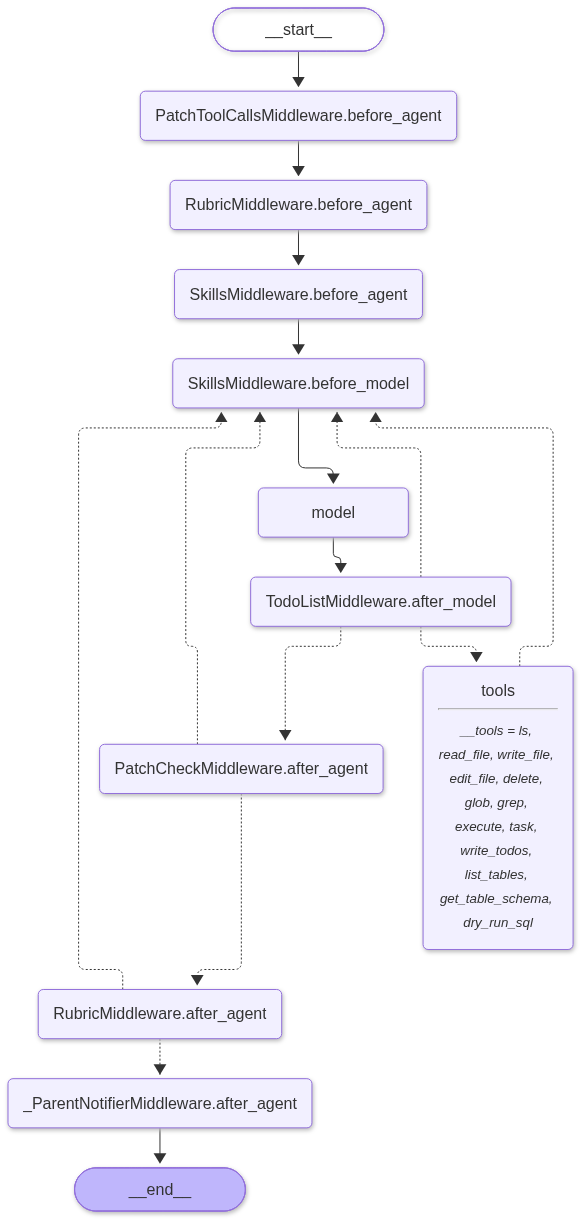

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools<hr/><small><em>__tools = ls, read_file, write_file, edit_file, delete, glob, grep, execute, task, write_todos, list_tables, get_table_schema, dry_run_sql</em></small>)
	_ParentNotifierMiddleware\2eafter_agent(_ParentNotifierMiddleware.after_agent)
	PatchToolCallsMiddleware\2ebefore_agent(PatchToolCallsMiddleware.before_agent)
	TodoListMiddleware\2eafter_model(TodoListMiddleware.after_model)
	RubricMiddleware\2ebefore_agent(RubricMiddleware.before_agent)
	RubricMiddleware\2eafter_agent(RubricMiddleware.after_agent)
	PatchCheckMiddleware\2eafter_agent(PatchCheckMiddleware.after_agent)
	SkillsMiddleware\2ebefore_agent(SkillsMiddleware.before_agent)
	SkillsMiddleware\2ebefore_model(SkillsMiddleware.before_model)
	__end__([<p>__end__</p>]):::last
	PatchCheckMiddleware\2eafter_agent -.-> RubricMiddleware\2eafter_agent;
	PatchCheckMiddleware\2eafter_agent -.-> SkillsMiddl

In [44]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))   # renders through mermaid.ink, an external service
print(agent.get_graph().draw_mermaid())                # text; paste into mermaid.live or a VS Code mermaid preview

In [45]:
# ---- Phases 4 to 6: apply to dev, verify in a clean sandbox, judge ----
# The sandbox is deleted. The agent's edits existed only in the sandbox's clone, and the patch is all that came out.
# patch_check built and validated it on the agent's last pass; these exact bytes are the ones shipped. Only a patch that
# passed validation goes on to be applied and verified.

if agent_run.answer.blocking_questions:
    # The agent stopped to ask questions before building anything: there is no patch to validate, apply or verify,
    # and no checks to run.
    patch_bytes, patch_ok, patch_files, changed_paths = b"", False, [], []
    apply_patch_result, clean_sandbox_verification, final_checks = None, None, None
else:
    patch_bytes = patch_check.patch_bytes
    patch_ok = not (patch_check.fixable_violations or patch_check.unfixable_violations)
    patch_files = read_patch(patch_bytes) if patch_ok else []
    changed_paths = [file.path for file in patch_files]

    # the patch applied to a fresh clone of dev, as the job will apply it
    apply_patch_result = apply_patch_and_push(patch_bytes, sandbox_start_commit, BASE_BRANCH, new_branch=PUSH_NEW_BRANCH,
                                            commit_message=f"agent: {TASK_NAME} (notebook run)") if patch_ok else None
    # apply, compile, dependencies, ruff and pytest in a second, clean sandbox
    clean_sandbox_verification = None
    if patch_ok:
        clean_sandbox_verification = await asyncio.to_thread(verify_patch_in_clean_sandbox, client, snapshot_id, patch_bytes, changed_paths,
                                                             apply_patch_result.dev_moved, sandbox_start_commit, BASE_BRANCH)
    # the checks every task gets, and whether they passed
    final_checks = build_final_checks(patch_check.fixable_violations + patch_check.unfixable_violations,
                                      apply_patch_result, clean_sandbox_verification)
# what a run produced, as it is stored for the main agent
coding_agent_result = build_coding_result(agent_run, patch_files, apply_patch_result, final_checks)


[ 102s] second sandbox: repo cloned
[ 111s] second sandbox: compile finished
[ 117s] second sandbox: dependencies installed
[ 132s] second sandbox: Python checks finished


In [46]:
# Notebook only: statistics from the agent's messages, and the checks that belong to one test task.
# In production, task-specific checks come from the plan; final_checks.passed is the generic verdict.
failed_file_edits = [m for m in agent_result["messages"] if isinstance(m, ToolMessage) and m.name in ("edit_file", "write_file") and m.status == "error"]
tool_calls = [tool_call for m in agent_result["messages"] if isinstance(m, AIMessage) for tool_call in m.tool_calls]
dry_runs = [m for m in agent_result["messages"] if isinstance(m, ToolMessage) and m.name == "dry_run_sql"]

notebook_checks = []
if clean_sandbox_verification is not None:
    # the aisle pacing tasks add the column user_aisle_pacing_ratio to the final table
    if TASK_NAME.startswith("aisle_pacing"):
        compiled_final_table = next((t for t in final_checks.compiled_tables if t["target"]["name"] == "final_ml_features_table"), None)
        notebook_checks.append(("new feature is in the compiled final table", bool(compiled_final_table) and "user_aisle_pacing_ratio" in compiled_final_table["query"]))
    # these tasks add a test
    if TASK_NAME.startswith("aisle_pacing_lgbm_ranker") or TASK_NAME == "aisle_pacing_all_models_edit_notebook":
        notebook_checks.append(("a test was added and passes", clean_sandbox_verification.pytest is not None and clean_sandbox_verification.pytest.exit_code == 0))
    # the notebook task adds a notebook
    if TASK_NAME == "aisle_pacing_lgbm_ranker_w_test_notebook":
        notebook_checks.append(("a notebook was added", any(path.endswith(".ipynb") for path in changed_paths)))
    # the edit task changes the evaluation notebook in place: a display name for the new feature, and nothing rewritten
    if TASK_NAME == "aisle_pacing_all_models_edit_notebook":
        patch_text = patch_bytes.decode("utf-8", errors="replace")
        evaluation_diff = next((section for section in patch_text.split("diff --git ")[1:] if section.startswith("a/Notebooks/evaluation/model_evaluation.ipynb")), "")
        added_lines = [line for line in evaluation_diff.splitlines() if line.startswith("+") and not line.startswith("+++")]
        notebook_checks.append(("the evaluation notebook names the new feature", any("user_aisle_pacing_ratio" in line for line in added_lines)))
        notebook_checks.append(("the evaluation notebook was edited in place, not rewritten", 0 < len(added_lines) < 10))
    # the column description task documents the columns of every compiled table and changes no SQL
    if TASK_NAME == "column_descriptions":
        described_tables = [table for table in final_checks.compiled_tables if table.get("actionDescriptor", {}).get("columns")]
        notebook_checks.append(("every compiled table has column descriptions", bool(final_checks.compiled_tables) and len(described_tables) == len(final_checks.compiled_tables)))
        patch_text = patch_bytes.decode("utf-8", errors="replace")
        sqlx_sections = [section for section in patch_text.split("diff --git ")[1:] if ".sqlx" in section.splitlines()[0]]
        removed_lines = [line for section in sqlx_sections for line in section.splitlines() if line.startswith("-") and not line.startswith("---")]
        notebook_checks.append(("no SQL line was changed except description lines", all("description:" in line for line in removed_lines)))
    # the weekday count fix: running counts by window in the two wide tables, the same output columns, and nothing outside the expected files
    if TASK_NAME == "cumulative_weekday_counts":
        queries = {table["target"]["name"]: table["query"] for table in final_checks.compiled_tables}
        wide_tables = {"prelim_user_order_dow_wide": [f"user_product_same_dow_count_{k}" for k in range(7)],
                       "prelim_user_order_tod_wide": [f"user_product_same_tod_count_{part}" for part in ("morning", "afternoon", "evening", "nighttime")]}
        for table_name, columns in wide_tables.items():
            query = queries.get(table_name, "")
            notebook_checks.append((f"{table_name} counts with windows and keeps its columns", "OVER" in query and "SUM(CASE WHEN" not in query and all(column in query for column in columns)))
        expected_files = {"definitions/silver/prelim_user_order_dow_wide.sqlx", "definitions/silver/prelim_user_order_tod_wide.sqlx",
                          "definitions/gold/skeleton_features.sqlx", "definitions/gold/final_ml_features_table.sqlx"}
        notebook_checks.append(("only the expected files changed", set(changed_paths) <= expected_files))
all_checks = [(check.name, check.passed) for check in (final_checks.checks if final_checks else [])] + notebook_checks
failed_all = [label for label, ok in all_checks if not ok]

In [48]:
# Notebook only: print the results, one labelled section at a time.
def describe_tokens(counts):
    """One line of token use, including how much of the input came from the prefix cache."""
    if counts is None or not counts.input:
        return "none"
    uncached = counts.input - counts.cache_read - counts.cache_write
    return (f"{counts.input:,} input = {counts.cache_read:,} read from cache ({counts.cache_read / counts.input:.0%}) + "
            f"{counts.cache_write:,} written to cache + {uncached:,} uncached; {counts.output:,} output")


section("1. THE AGENT'S OWN ANSWER (its account of what it did; not verified)")
if stopped_early:
    print(f"The agent stopped before finishing: {stopped_early}\nIts todo list at that point:")
    for todo in agent_result.get("todos", []):
        print(f"  [{todo['status']}] {todo['content']}")
else:
    print(coding_agent_result.report or "(no report: the agent stopped to ask blocking questions)")
    for label, items in (("Assumptions", coding_agent_result.assumptions), ("Blocking questions", coding_agent_result.blocking_questions),
                         ("Follow-up questions", coding_agent_result.follow_up_questions)):
        if items:
            print(f"\n{label}:")
            for item in items:
                print(f"  - {item}")

section("2. WHAT THE AGENT DID (every tool call, in order)")
for call in tool_calls:
    print(f"  {call['name']:<12}", {k: str(v)[:70] for k, v in call["args"].items()})
print(f"\n  {len(tool_calls)} tool calls; {len(failed_file_edits)} failed edit_file / write_file calls", {m.content[:80] for m in failed_file_edits} if failed_file_edits else "")
print(f"  tokens, agent:    {describe_tokens(coding_agent_result.token_usage.agent)}")
print(f"  tokens, reviewer: {describe_tokens(coding_agent_result.token_usage.reviewer)}")
print(f"  dry runs: {len(dry_runs)}, {sum(m.status != 'error' for m in dry_runs)} valid")

section("2b. THE GRADER'S ROUNDS (the rubric review run before the agent finished)")
for evaluation in rubric_evaluations:
    print(f"  round {evaluation['iteration'] + 1}: {evaluation['result']}. {evaluation['explanation']}")
    for criterion in evaluation["criteria"]:
        print(f"    {'pass' if criterion['passed'] else 'FAIL'}  {criterion['name']}" + ("" if criterion["passed"] else f" -> {criterion['gap']}"))

section("3. THE PATCH (built in the agent's sandbox by patch_check)")
print("agent made commits:", "yes (the changes are still collected against the sandbox start commit)" if sandbox_end_commit != sandbox_start_commit else "no")
print("line endings restored for:", patch_check.restored_endings.replace("line endings restored: ", "").replace("\n", ", ") or "no modified files")
print("patch-check retries (the agent sent back to fix problems):", patch_check.retries)
print("\nfiles changed, as git reads the patch:")
print(subprocess.run(["git", "apply", "--stat", "--summary"], input=patch_bytes, capture_output=True, cwd=tempfile.gettempdir()).stdout.decode("utf-8", errors="replace"))

section("4. PATCH VALIDATION AND APPLY (what the job does with the patch)")
print("patch validation:", "not run: the agent stopped to ask blocking questions" if agent_run.answer.blocking_questions else "passed" if patch_ok
      else f"FAILED ({len(patch_check.fixable_violations)} fixable, {len(patch_check.unfixable_violations)} unfixable)")
for message in patch_check.fixable_violations:
    print("  fixable:", message)
for message in patch_check.unfixable_violations:
    print("  unfixable:", message)
if apply_patch_result is not None:
    print(f"commit the sandbox started from: {sandbox_start_commit[:7]}; dev now: {apply_patch_result.dev_commit[:7]}; dev moved: {'yes' if apply_patch_result.dev_moved else 'no'}")
    print(f"patch applied: {'yes' if apply_patch_result.applied else 'NO: ' + apply_patch_result.error}" + (" (needs_rebase)" if final_checks.needs_rebase else ""))
    print(apply_patch_result.diffstat)

section("5. VERIFICATION IN A CLEAN SANDBOX (second sandbox; this is the recorded result)")
if clean_sandbox_verification is None:
    print("not run: the patch did not pass validation")
else:
    print(f"patch applied in the second sandbox: {'yes' if clean_sandbox_verification.apply.exit_code == 0 else 'NO: ' + clean_sandbox_verification.apply.stderr.strip()}")
    if clean_sandbox_verification.compile is not None:
        print(f"dataform compile: exit {clean_sandbox_verification.compile.exit_code}, {len(final_checks.compiled_tables)} tables, {len(final_checks.compile_errors)} compilation errors")
        for error in final_checks.compile_errors:
            print("   ", error.get("path"), "-", error.get("message", "")[:200])
    if clean_sandbox_verification.dependencies is not None:
        print(f"\ndependencies from requirements.txt: exit {clean_sandbox_verification.dependencies.exit_code}")
        print("\n".join((clean_sandbox_verification.dependencies.stderr or clean_sandbox_verification.dependencies.stdout).strip().splitlines()[-6:]))
    if clean_sandbox_verification.pytest is not None:
        print("\nPython files changed:", ", ".join(path for path in changed_paths if path.endswith(".py")))
        if clean_sandbox_verification.ruff is not None:
            print(f"ruff (syntax and undefined names): exit {clean_sandbox_verification.ruff.exit_code}", clean_sandbox_verification.ruff.stdout.strip()[-600:] if clean_sandbox_verification.ruff.exit_code else "")
        print(f"pytest: exit {clean_sandbox_verification.pytest.exit_code}" + (" (no tests collected)" if clean_sandbox_verification.pytest.exit_code == 5 else ""))
        print("\n".join(clean_sandbox_verification.pytest.stdout.strip().splitlines()[-8:]))

section("SUMMARY")
for label, ok in all_checks:
    print(f"  {'PASS' if ok else 'FAIL'}  {label}")
print("\n  STOPPED TO ASK QUESTIONS" if agent_run.answer.blocking_questions
      else f"\n  TASK {'PASSED' if not failed_all else 'FAILED: ' + '; '.join(failed_all)}")
print(f"  info  {len(changed_paths)} paths changed, {len(failed_file_edits)} failed file-edit calls, {time.perf_counter() - start_time:.0f}s total")
if rubric_evaluations:
    last_evaluation = rubric_evaluations[-1]
    print(f"  info  reviewer: {last_evaluation['result']} after {len(rubric_evaluations)} rounds")
    for criterion in last_evaluation["criteria"]:
        if not criterion["passed"]:
            print(f"          still failing: {criterion['name']} -> {criterion['gap']}")

section("7. THE CODING AGENT RESULT (what is stored for the main agent)")
result_json = json.dumps(asdict(coding_agent_result), indent=2)
print(result_json)
print(f"\n{len(result_json):,} characters (a Firestore document holds about 1 MiB)")



1. THE AGENT'S OWN ANSWER (its account of what it did; not verified)
1. Files changed:
- `src/utilities/utility_functions.py`: added `find_near_duplicate_names(names, threshold=90)`. It scores every pair from `itertools.combinations` with `rapidfuzz.fuzz.ratio`. It keeps pairs scoring at least `threshold` and returns `(name_a, name_b, score)` tuples, each pair once, sorted highest score first. I added the imports `from itertools import combinations` and `from rapidfuzz import fuzz`.
- `requirements.txt`: added `rapidfuzz`. The file had no trailing newline, so I also put `pytest` and `rapidfuzz` on separate lines.
- `tests/test_utility_functions.py` (new): two small tests. The first checks that similar pairs are returned once, in descending score order, and that all scores are at least the threshold. It also checks that an unrelated name is excluded. The second checks that dissimilar names return `[]` and that an identical pair scores 100 at `threshold=100`. The test adds `src` to `sys

In [11]:
Path(tempfile.gettempdir(), "last_coding_agent_patch.diff").write_bytes(patch_bytes)
print(Path(tempfile.gettempdir(), "last_coding_agent_patch.diff"))

C:\Users\jmhla\AppData\Local\Temp\last_coding_agent_patch.diff


In [38]:
from deepagents import FilesystemMiddleware, HarnessProfile, create_deep_agent, register_harness_profile
default_descriptions = {tool.name: tool.description for tool in FilesystemMiddleware(backend=LangSmithSandbox(sandbox)).tools}

display(default_descriptions)

{'ls': 'Lists all files in a directory.\n\nThis is useful for exploring the filesystem and finding the right file to read or edit.\nYou should almost ALWAYS use this tool before using the read_file or edit_file tools.',
 'read_file': 'Reads a file from the filesystem. Assume any path the user provides is valid; reading a missing file returns an error.\n\nUsage:\n- By default, it reads up to 100 lines starting from the beginning of the file. Use `offset`/`limit` to page through large files instead of reading them whole.\n- A status header, `@@ field | field | ... @@`, sits above the file content, and every line after it is verbatim file content. When content is truncated, there may be an explanation before the header. Never include the header when editing.\n- Speculatively batch multiple `read_file` calls in one response when several files may be useful.\n- An empty file returns a system-reminder warning in place of contents.\n- Large tool results may be offloaded to a file; the tool me

In [ ]:
one_call_rule = ("\n\nDo not call this tool more than once for the same file in a single response: "
                     "combine changes to one file into one call, or make them in separate steps.")
display({
        name: default_descriptions[name] + one_call_rule for name in ("edit_file", "write_file")})